# Comprehensive Mutual Funds EDA (India)

Exploratory analysis of 814 Indian mutual fund schemes using only **NumPy, pandas and Matplotlib**.

Run from the `notebooks/` folder so the relative path `../data/` resolves. See the project README for the full overview.


In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [61]:
df = pd.read_csv('../data/comprehensive_mutual_funds_data.csv')
display(df.head())

,scheme_name,min_sip,min_lumpsum,expense_ratio,fund_size_cr,fund_age_yr,fund_manager,sortino,alpha,sd,beta,sharpe,risk_level,amc_name,rating,category,sub_category,returns_1yr,returns_3yr,returns_5yr
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,100,100,0.27,10.0,10,Kaustubh Gupta,0.32,2.24,9.39,0.01,0.24,3,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,4.0,6.5,6.9
1,Aditya Birla SL Arbitrage Fund,1000,1000,0.36,4288.0,10,Lovelish Solanki,1.33,1.53,0.72,0.56,1.1,1,Aditya Birla Sun Life Mutual Fund,3,Hybrid,Arbitrage Mutual Funds,5.6,4.8,5.5
2,Aditya Birla SL Asset Allocator FoF-Dir Growth,1000,1000,0.53,157.0,10,Vinod Narayan Bhat,3.44,2.67,10.58,0.67,1.42,5,Aditya Birla Sun Life Mutual Fund,3,Other,FoFs Domestic,2.0,18.9,9.7
3,Aditya Birla SL Bal Bhavishya Yojna – Dir Growth,500,1000,0.76,637.0,4,Atul Penkar,2.18,-6.37,14.99,0.85,0.9,6,Aditya Birla Sun Life Mutual Fund,2,Solution Oriented,Childrens Funds,-0.7,17.1,NaN
4,Aditya Birla SL Balanced Advantage Fund,100,100,0.61,6386.0,10,Mohit Sharma,3.69,1.99,10.38,0.68,1.39,6,Aditya Birla Sun Life Mutual Fund,4,Hybrid,Dynamic Asset Allocation or Balanced Advantage,4.5,18.6,9.7


In [62]:
# Clean the specified numeric columns by converting '-' values to NaN
numeric_cols = ['sortino', 'alpha', 'sd', 'beta', 'sharpe']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Display summary info to verify the data types
print(df[numeric_cols].info())
display(df[numeric_cols].head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 814 entries, 0 to 813
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   sortino  791 non-null    float64
 1   alpha    772 non-null    float64
 2   sd       790 non-null    float64
 3   beta     772 non-null    float64
 4   sharpe   791 non-null    float64
dtypes: float64(5)
memory usage: 31.9 KB
None


,sortino,alpha,sd,beta,sharpe
0,0.32,2.24,9.39,0.01,0.24
1,1.33,1.53,0.72,0.56,1.10
2,3.44,2.67,10.58,0.67,1.42
3,2.18,-6.37,14.99,0.85,0.90
4,3.69,1.99,10.38,0.68,1.39


In [63]:
# 1. Identify and inspect duplicated scheme names
duplicates = df[df.duplicated(subset=['scheme_name'], keep=False)]
print(f"Total duplicated rows by scheme_name: {len(duplicates)}")
print("Example of duplicate scheme names:")
display(duplicates[['scheme_name', 'amc_name', 'category', 'returns_1yr']].head(6))

# Deduplicate by keeping the first occurrence
df_clean = df.drop_duplicates(subset=['scheme_name'], keep='first').copy()
print(f"Dataset shape after deduplication: {df_clean.shape}")

Total duplicated rows by scheme_name: 38
Example of duplicate scheme names:


,scheme_name,amc_name,category,returns_1yr
75,AXIS Retirement Savings Fund,Axis Mutual Fund,Solution Oriented,-1.3
76,AXIS Retirement Savings Fund,Axis Mutual Fund,Solution Oriented,-2.5
77,AXIS Retirement Savings Fund,Axis Mutual Fund,Solution Oriented,-4.1
94,Bank of India Midcap Tax Fund,Bank of India Mutual Fund,Equity,-4.1
95,Bank of India Midcap Tax Fund,Bank of India Mutual Fund,Equity,-4.7
241,HDFC Index Fund,HDFC Mutual Fund,Other,2.4


Dataset shape after deduplication: (789, 20)


In [64]:
# 2. Analyze outliers in 'returns_1yr' using the IQR (Interquartile Range) method manually with numpy/pandas
q1 = df_clean['returns_1yr'].quantile(0.25)
q3 = df_clean['returns_1yr'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df_clean[(df_clean['returns_1yr'] < lower_bound) | (df_clean['returns_1yr'] > upper_bound)]
print(f"Outlier limits for 1-year returns: {lower_bound:.2f}% to {upper_bound:.2f}%")
print(f"Number of outliers found: {len(outliers)}")
print("Top outliers (highest/lowest returns_1yr):")
display(outliers[['scheme_name', 'category', 'returns_1yr']].sort_values(by='returns_1yr', ascending=False).head(5))

Outlier limits for 1-year returns: -4.40% to 11.60%
Number of outliers found: 88
Top outliers (highest/lowest returns_1yr):


,scheme_name,category,returns_1yr
89,Bank of India Credit Risk Fund,Debt,130.8
97,Bank of India Short Term Income – Direct Growth,Debt,28.3
321,ICICI Pru Infrastructure Fund,Equity,24.3
451,Kotak Infrastructure & Ecoc. Reform-SP-DirGrowth,Equity,23.2
88,Bank of India Conservative Hybrid Fund,Hybrid,22.3


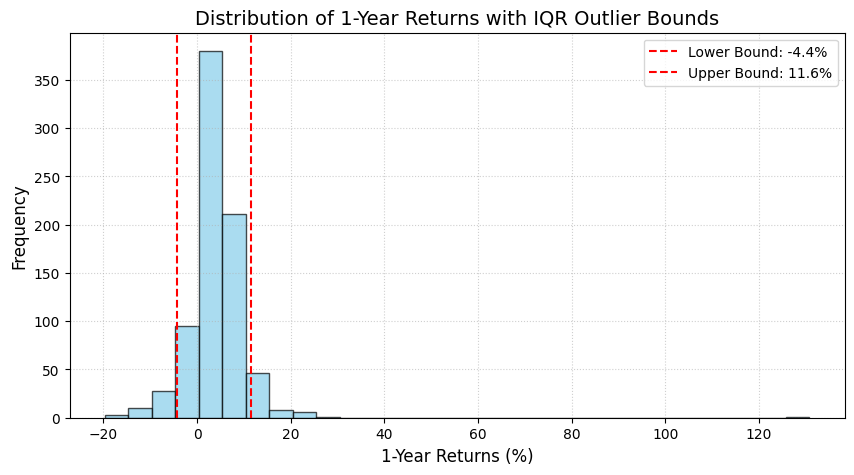

In [65]:
# 3. Plot the distribution of 1-year returns and identify outliers visually
plt.figure(figsize=(10, 5))
plt.hist(df_clean['returns_1yr'].dropna(), bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(lower_bound, color='red', linestyle='dashed', linewidth=1.5, label=f'Lower Bound: {lower_bound:.1f}%')
plt.axvline(upper_bound, color='red', linestyle='dashed', linewidth=1.5, label=f'Upper Bound: {upper_bound:.1f}%')
plt.title('Distribution of 1-Year Returns with IQR Outlier Bounds', fontsize=14)
plt.xlabel('1-Year Returns (%)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

Spearman's Rank Correlation between Risk Level and 1-Year Returns: -0.327


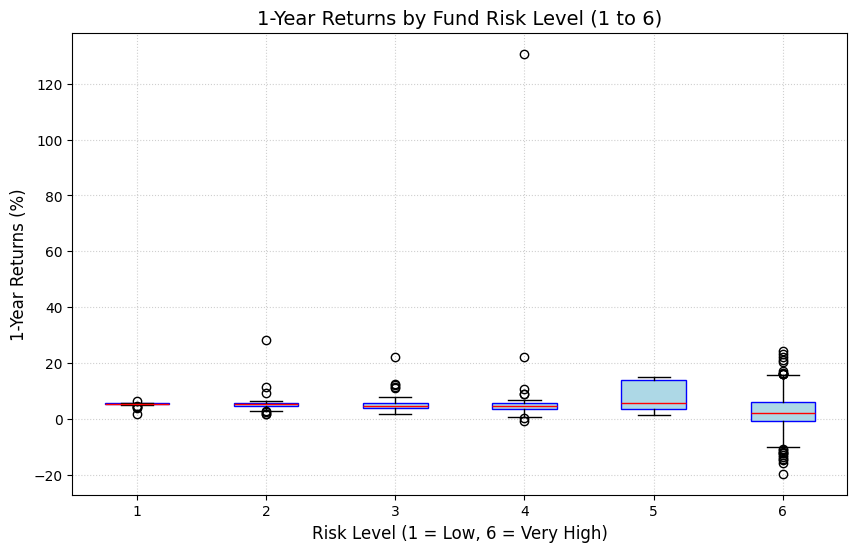

In [66]:
# 4. Manually calculate a rank-based correlation (Spearman's Rank Correlation) between Risk Level and 1-Year Returns
# using only pandas/numpy functions as per the STRICT rules.
r_corr = df_clean[['risk_level', 'returns_1yr']].corr(method='spearman').iloc[0, 1]
print(f"Spearman's Rank Correlation between Risk Level and 1-Year Returns: {r_corr:.3f}")

# Scatter/box representation using matplotlib
plt.figure(figsize=(10, 6))
# Group by risk level and collect returns for boxplot representation
risk_groups = [df_clean[df_clean['risk_level'] == r]['returns_1yr'].dropna().values for r in sorted(df_clean['risk_level'].unique())]
plt.boxplot(risk_groups, tick_labels=sorted(df_clean['risk_level'].unique()), patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='blue'),
            medianprops=dict(color='red'))
plt.title('1-Year Returns by Fund Risk Level (1 to 6)', fontsize=14)
plt.xlabel('Risk Level (1 = Low, 6 = Very High)', fontsize=12)
plt.ylabel('1-Year Returns (%)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [67]:
# Filter for Equity funds and clean necessary columns
equity_df = df_clean[df_clean['category'] == 'Equity'].copy()

# Ensure we have numeric types for returns_3yr, sharpe, and sortino
equity_df['returns_3yr'] = pd.to_numeric(equity_df['returns_3yr'], errors='coerce')
equity_df['sharpe'] = pd.to_numeric(equity_df['sharpe'], errors='coerce')
equity_df['sortino'] = pd.to_numeric(equity_df['sortino'], errors='coerce')

# Drop rows with nulls in these key evaluation columns for ranking integrity
equity_eval = equity_df.dropna(subset=['returns_3yr', 'sharpe', 'sortino']).copy()

# Rank the funds (higher values get rank 1, using method='min' or descending order)
# Lower rank number = better performance
equity_eval['rank_return_3yr'] = equity_eval['returns_3yr'].rank(ascending=False, method='min')
equity_eval['rank_sharpe'] = equity_eval['sharpe'].rank(ascending=False, method='min')
equity_eval['rank_sortino'] = equity_eval['sortino'].rank(ascending=False, method='min')

print(f"Number of Equity funds evaluated for rankings: {len(equity_eval)}")

Number of Equity funds evaluated for rankings: 293


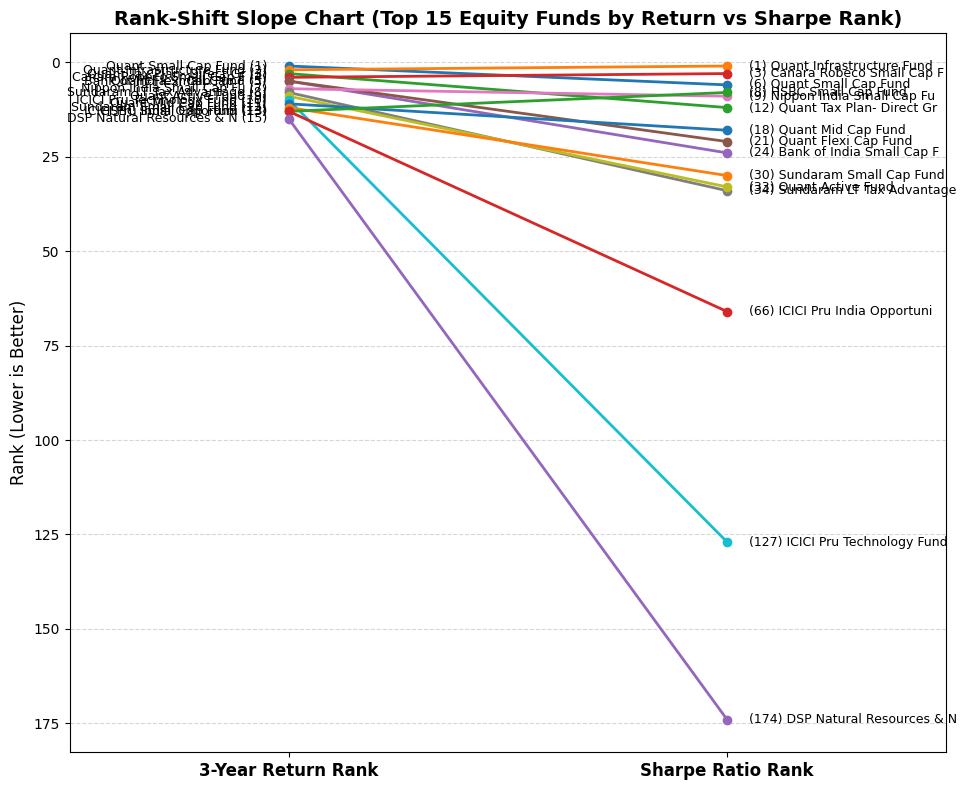

In [68]:
# Select top 15 funds by 3-year return rank to build the Rank-Shift Slope Chart
top15_returns = equity_eval.nsmallest(15, 'rank_return_3yr')

plt.figure(figsize=(10, 8))

# Plot the ranks
for i, row in top15_returns.iterrows():
    # x = 1 for return rank, x = 2 for Sharpe rank
    plt.plot([1, 2], [row['rank_return_3yr'], row['rank_sharpe']], marker='o', linewidth=2, label=row['scheme_name'][:30])
    # Add labels on left and right
    plt.text(0.95, row['rank_return_3yr'], f"{row['scheme_name'][:25]} ({int(row['rank_return_3yr'])})", ha='right', va='center', fontsize=9)
    plt.text(2.05, row['rank_sharpe'], f"({int(row['rank_sharpe'])}) {row['scheme_name'][:25]}", ha='left', va='center', fontsize=9)

plt.xlim(0.5, 2.5)
plt.xticks([1, 2], ['3-Year Return Rank', 'Sharpe Ratio Rank'], fontsize=12, fontweight='bold')
plt.ylabel('Rank (Lower is Better)', fontsize=12)
plt.title('Rank-Shift Slope Chart (Top 15 Equity Funds by Return vs Sharpe Rank)', fontsize=14, fontweight='bold')
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
# Invert y-axis because rank 1 (top) should be at the top of the chart
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [69]:
# Median values for returns and Sharpe to categorize gems and overrated funds
median_return = equity_eval['returns_3yr'].median()
median_sharpe = equity_eval['sharpe'].median()

print(f"Median 3-Year Return: {median_return:.2f}%")
print(f"Median Sharpe Ratio: {median_sharpe:.2f}\n")

# 1. Hidden Gems: below-median return but high Sharpe ratio
# Filter and sort by descending Sharpe ratio
hidden_gems = equity_eval[(equity_eval['returns_3yr'] < median_return) & (equity_eval['sharpe'] > median_sharpe)]
hidden_gems = hidden_gems.sort_values(by='sharpe', ascending=False).head(10)

print("=== Top 10 Hidden Gems (High Sharpe, Below-Median Return) ===")
display(hidden_gems[['scheme_name', 'returns_3yr', 'sharpe', 'sortino', 'rank_return_3yr', 'rank_sharpe']])

# 2. Overrated: high return but low Sharpe ratio
# Filter and sort by descending returns_3yr
overrated_funds = equity_eval[(equity_eval['returns_3yr'] > median_return) & (equity_eval['sharpe'] < median_sharpe)]
overrated_funds = overrated_funds.sort_values(by='returns_3yr', ascending=False).head(10)

print("\n=== Top 10 Overrated Funds (High Return, Low Sharpe) ===")
display(overrated_funds[['scheme_name', 'returns_3yr', 'sharpe', 'sortino', 'rank_return_3yr', 'rank_sharpe']])

Median 3-Year Return: 28.00%
Median Sharpe Ratio: 1.44

=== Top 10 Hidden Gems (High Sharpe, Below-Median Return) ===


,scheme_name,returns_3yr,sharpe,sortino,rank_return_3yr,rank_sharpe
504,Mirae Asset Great Consumer Fund,27.2,1.68,3.41,161.0,63.0
314,ICICI Pru FMCG Fund,24.5,1.61,3.73,223.0,76.0
301,ICICI Pru Bharat Consumption Fund,22.7,1.60,3.37,249.0,82.0
677,Sundaram Dividend Yield Fund,26.4,1.55,4.03,182.0,100.0
716,Tata Equity P/E Fund,27.8,1.54,3.31,149.0,105.0
699,Sundaram Mid Cap Fund,27.4,1.53,3.74,158.0,108.0
718,Tata Ethical Fund,27.9,1.53,2.75,148.0,108.0
287,HSBC Midcap Fund,26.1,1.53,3.33,189.0,108.0
133,Canara Robeco Equity Tax Saver Fund,27.7,1.51,3.08,151.0,117.0
810,UTI-Value Opportunities Fund,27.2,1.48,3.21,161.0,127.0



=== Top 10 Overrated Funds (High Return, Low Sharpe) ===


,scheme_name,returns_3yr,sharpe,sortino,rank_return_3yr,rank_sharpe
163,DSP Natural Resources & New Energy – Direct Gr...,44.3,1.39,2.31,15.0,174.0
715,Tata Digital India Fund,39.0,1.37,2.29,34.0,186.0
28,Aditya Birla SL Infrastructure Fund,35.6,1.40,3.30,50.0,165.0
243,HDFC Infrastructure Fund,34.3,1.30,3.12,62.0,206.0
355,IDBI Equity Advantage Fund,33.7,1.15,2.40,67.0,248.0
325,ICICI Pru Long Term Wealth Enhancement Fund,33.7,1.39,3.33,67.0,174.0
462,L&T India Large Cap Fund,33.0,1.18,2.60,80.0,242.0
550,Nippon India Focused Equity Fund,33.0,1.40,3.50,80.0,165.0
574,Nippon India US Equity Opportunities Fund,32.4,0.67,1.33,90.0,292.0
151,DSP Equity Opportunities Fund,31.6,1.40,2.87,93.0,165.0


In [70]:
def bootstrap_spearman_ci(data, col_x, col_y, num_resamples=1000, alpha=0.05):
    valid_data = data[[col_x, col_y]].dropna()
    if len(valid_data) < 10:
        return np.nan, np.nan, np.nan

    # Point estimate of Spearman correlation using rank and corr
    pe = valid_data[col_x].rank().corr(valid_data[col_y].rank())

    # Seeded random number generator
    rng = np.random.default_rng(42)
    boot_corrs = []
    n = len(valid_data)

    for _ in range(num_resamples):
        indices = rng.choice(n, size=n, replace=True)
        sample = valid_data.iloc[indices]
        corr = sample[col_x].rank().corr(sample[col_y].rank())
        boot_corrs.append(corr)

    boot_corrs = np.array(boot_corrs)
    lower = np.percentile(boot_corrs, (alpha / 2) * 100)
    upper = np.percentile(boot_corrs, (1 - alpha / 2) * 100)
    return pe, lower, upper


=== Analyzing Category: Equity (Total Funds: 296) ===
  returns_1yr vs Expense Ratio -> Spearman r: 0.073 | 95% CI: [-0.036, 0.178]
  returns_3yr vs Expense Ratio -> Spearman r: -0.126 | 95% CI: [-0.234, -0.014]
  returns_5yr vs Expense Ratio -> Spearman r: -0.416 | 95% CI: [-0.514, -0.299]


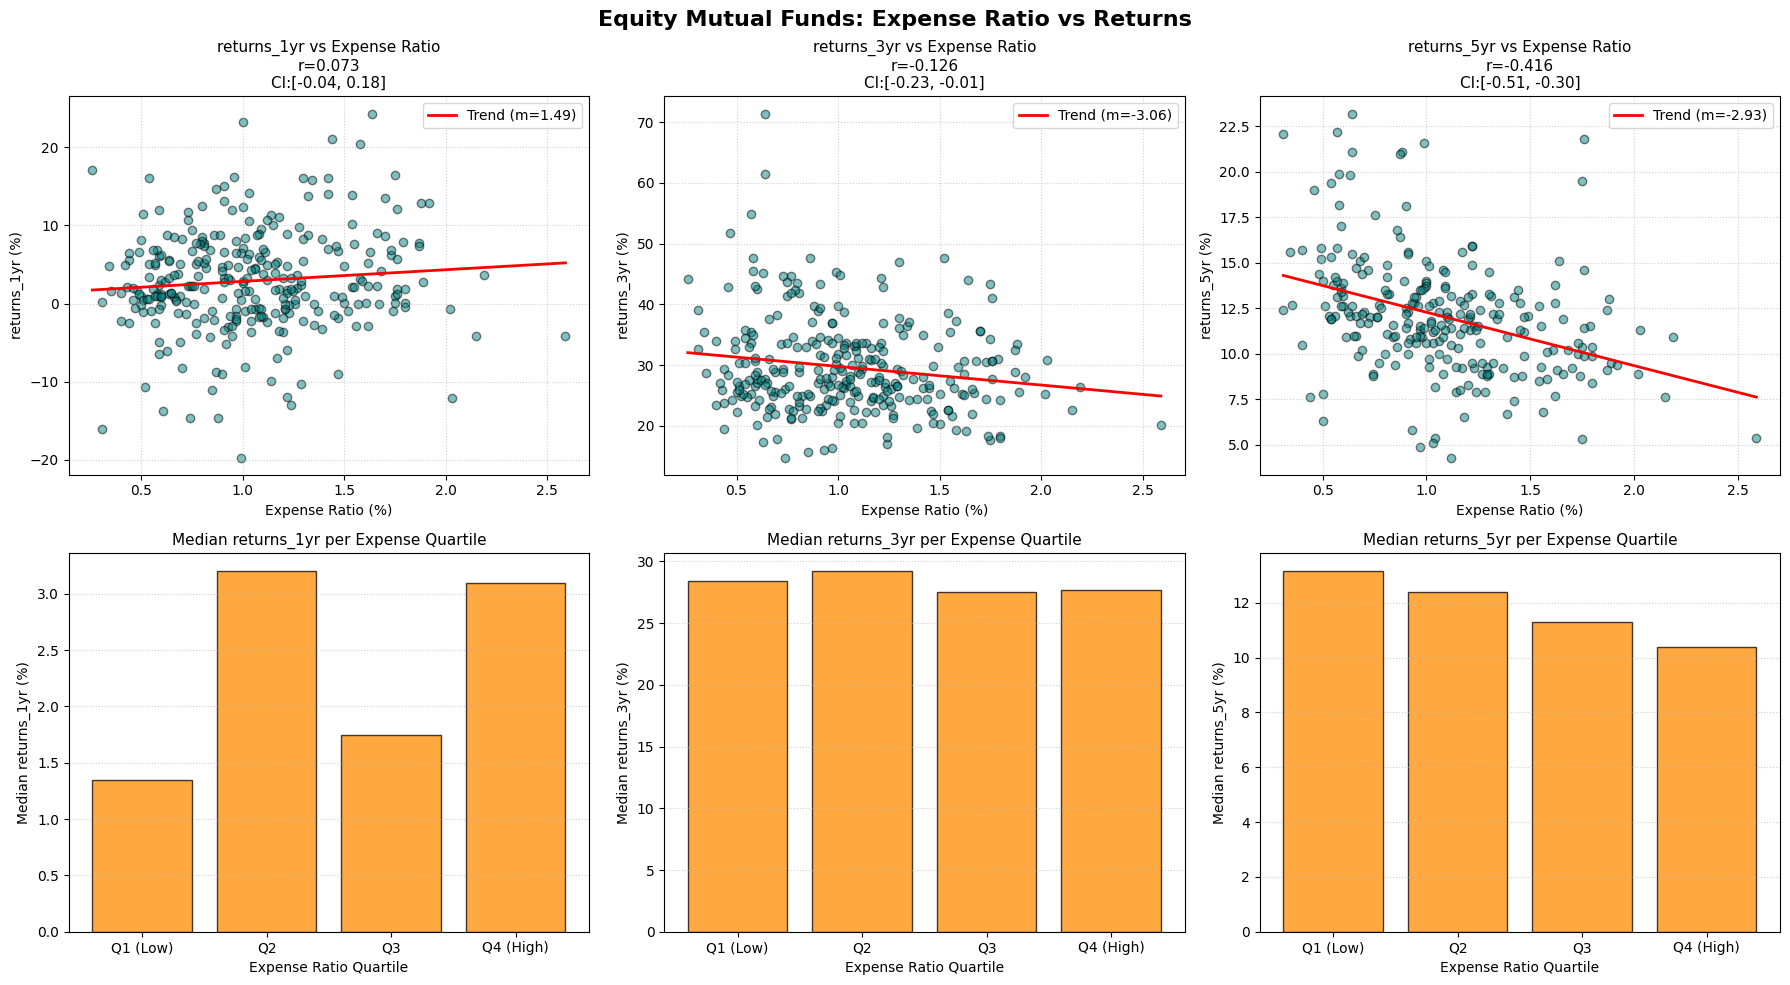


=== Analyzing Category: Debt (Total Funds: 281) ===
  returns_1yr vs Expense Ratio -> Spearman r: -0.297 | 95% CI: [-0.421, -0.166]
  returns_3yr vs Expense Ratio -> Spearman r: 0.582 | 95% CI: [0.477, 0.676]
  returns_5yr vs Expense Ratio -> Spearman r: 0.283 | 95% CI: [0.136, 0.425]


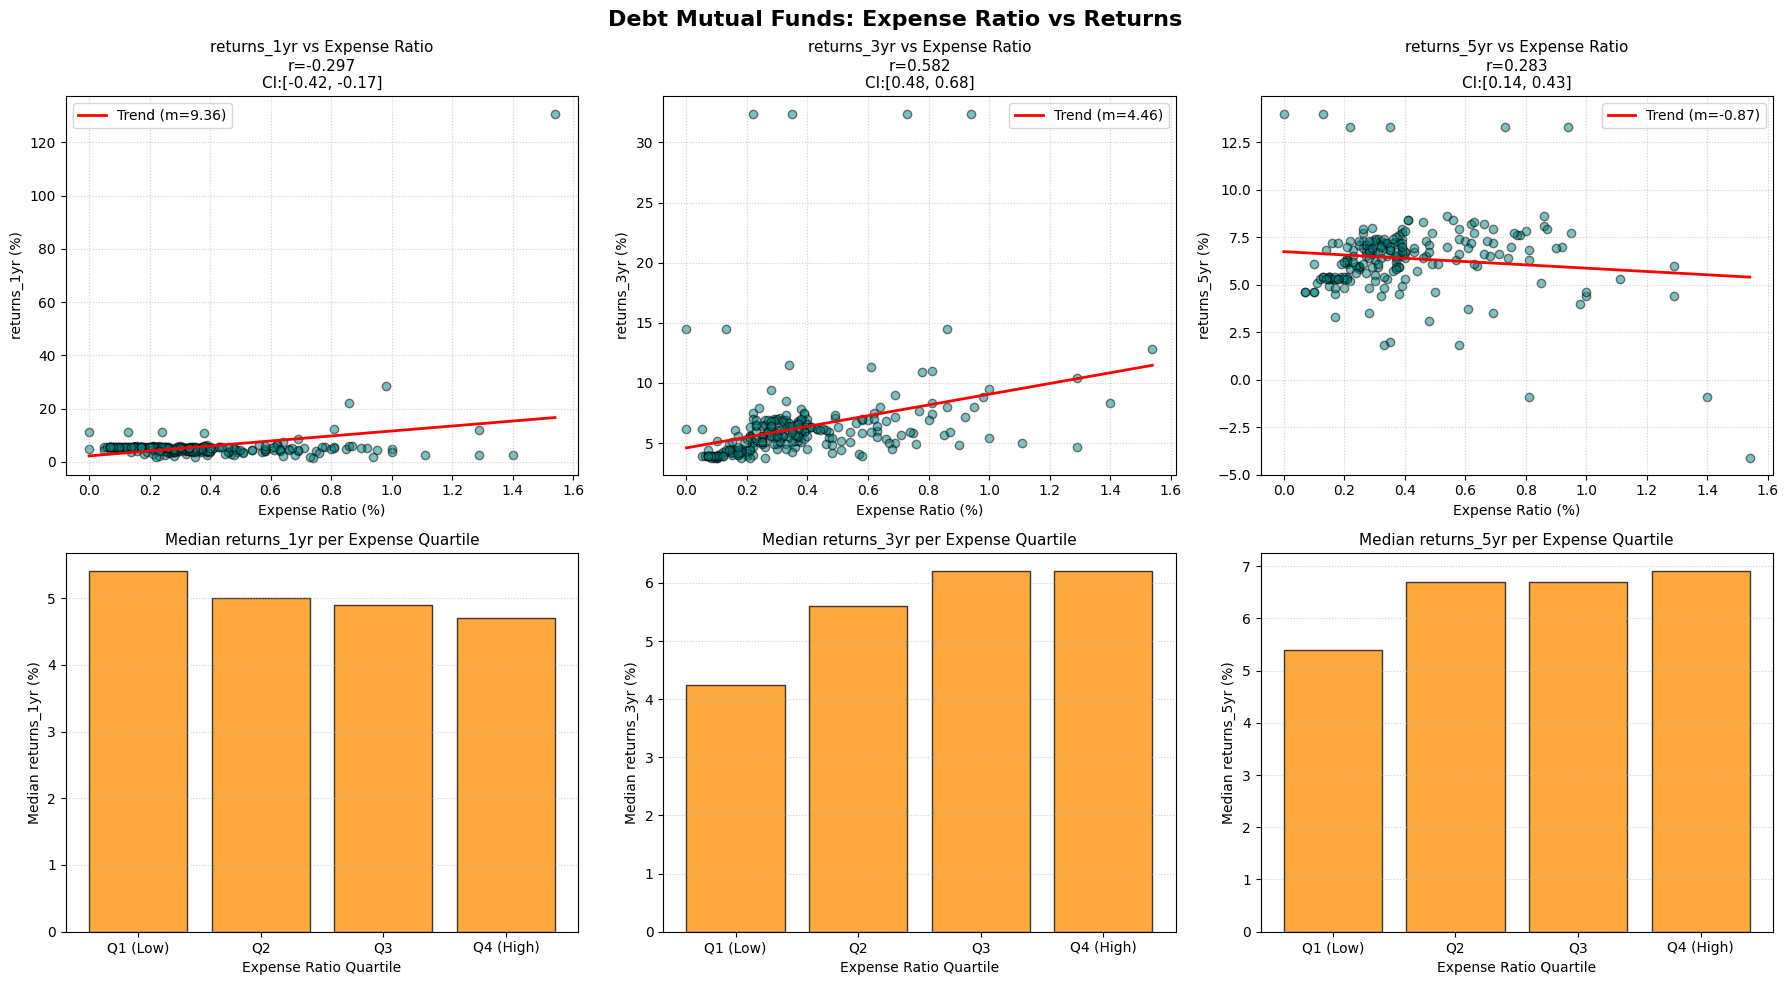


=== Analyzing Category: Hybrid (Total Funds: 116) ===
  returns_1yr vs Expense Ratio -> Spearman r: -0.189 | 95% CI: [-0.382, 0.017]
  returns_3yr vs Expense Ratio -> Spearman r: 0.346 | 95% CI: [0.154, 0.520]
  returns_5yr vs Expense Ratio -> Spearman r: 0.214 | 95% CI: [-0.015, 0.405]


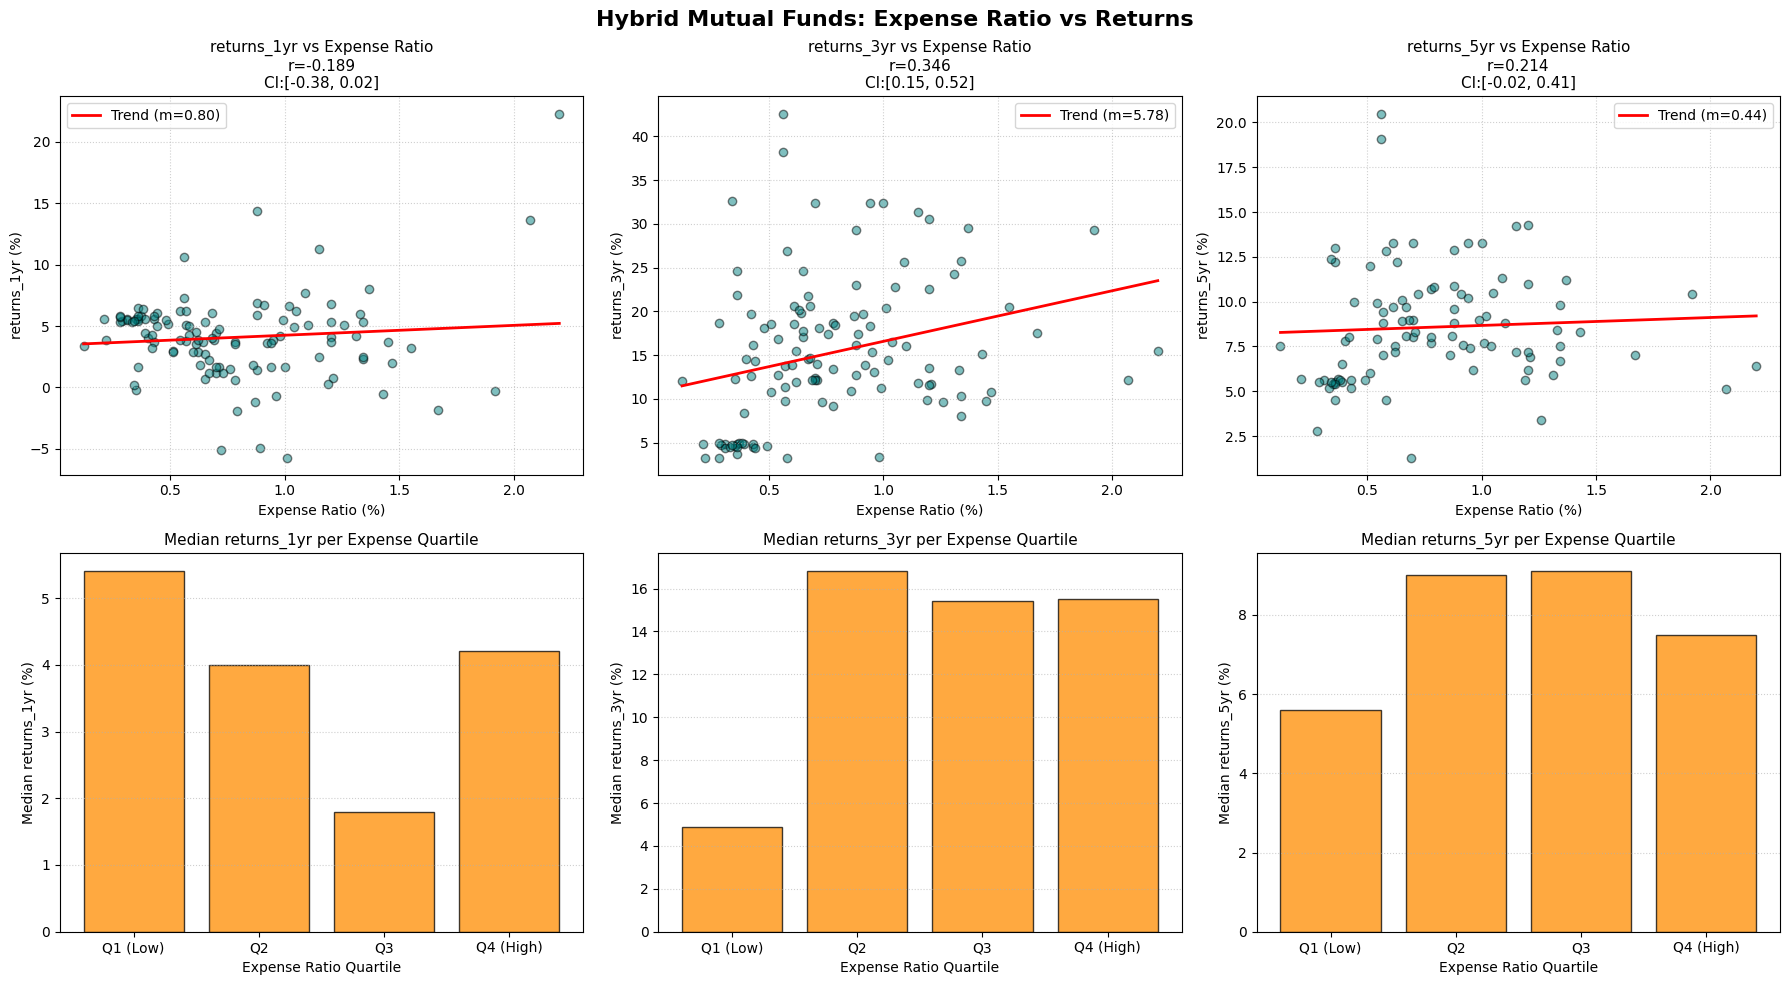

In [71]:
categories = ['Equity', 'Debt', 'Hybrid']
return_cols = ['returns_1yr', 'returns_3yr', 'returns_5yr']

for cat in categories:
    cat_df = df_clean[df_clean['category'] == cat].copy()
    print(f"\n=== Analyzing Category: {cat} (Total Funds: {len(cat_df)}) ===")

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(f"{cat} Mutual Funds: Expense Ratio vs Returns", fontsize=16, fontweight='bold')

    for idx, ret_col in enumerate(return_cols):
        valid_df = cat_df[['expense_ratio', ret_col]].dropna().copy()
        if len(valid_df) < 10:
            axes[0, idx].text(0.5, 0.5, "Insufficient Data", ha='center', va='center')
            axes[1, idx].text(0.5, 0.5, "Insufficient Data", ha='center', va='center')
            continue

        # Correlation & Bootstrap CI
        pe, lower, upper = bootstrap_spearman_ci(valid_df, 'expense_ratio', ret_col)
        print(f"  {ret_col} vs Expense Ratio -> Spearman r: {pe:.3f} | 95% CI: [{lower:.3f}, {upper:.3f}]")

        # Scatter Plot with Polyfit Trendline
        x = valid_df['expense_ratio'].values
        y = valid_df[ret_col].values
        axes[0, idx].scatter(x, y, alpha=0.5, color='teal', edgecolor='k')

        # Fit trendline using np.polyfit
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        axes[0, idx].plot(x_line, slope * x_line + intercept, color='red', linewidth=2, label=f'Trend (m={slope:.2f})')

        axes[0, idx].set_title(f"{ret_col} vs Expense Ratio\nr={pe:.3f}\nCI:[{lower:.2f}, {upper:.2f}]", fontsize=11)
        axes[0, idx].set_xlabel('Expense Ratio (%)')
        axes[0, idx].set_ylabel(f'{ret_col} (%)')
        axes[0, idx].legend()
        axes[0, idx].grid(True, linestyle=':', alpha=0.6)

        # Split Expense Ratio into Quartiles & Plot Median Returns
        try:
            valid_df['expense_quartile'] = pd.qcut(valid_df['expense_ratio'], q=4, labels=['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)'])
            median_returns = valid_df.groupby('expense_quartile', observed=False)[ret_col].median()

            axes[1, idx].bar(median_returns.index.astype(str), median_returns.values, color='darkorange', edgecolor='black', alpha=0.75)
            axes[1, idx].set_title(f"Median {ret_col} per Expense Quartile", fontsize=11)
            axes[1, idx].set_xlabel('Expense Ratio Quartile')
            axes[1, idx].set_ylabel(f'Median {ret_col} (%)')
            axes[1, idx].grid(axis='y', linestyle=':', alpha=0.6)
        except Exception as e:
            axes[1, idx].text(0.5, 0.5, f"Error: {str(e)}", ha='center', va='center')

    plt.tight_layout()
    plt.show()

In [74]:
def bootstrap_spearman_ci(data, col_x, col_y, num_resamples=1000, alpha=0.05):
    valid_data = data[[col_x, col_y]].dropna()
    if len(valid_data) < 10:
        return np.nan, np.nan, np.nan

    # Point estimate of Spearman correlation using pandas rank and corr
    pe = valid_data[col_x].rank().corr(valid_data[col_y].rank())

    # Seeded random number generator
    rng = np.random.default_rng(42)
    boot_corrs = []
    n = len(valid_data)

    for _ in range(num_resamples):
        indices = rng.choice(n, size=n, replace=True)
        sample = valid_data.iloc[indices]
        corr = sample[col_x].rank().corr(sample[col_y].rank())
        boot_corrs.append(corr)

    boot_corrs = np.array(boot_corrs)
    lower = np.percentile(boot_corrs, (alpha / 2) * 100)
    upper = np.percentile(boot_corrs, (1 - alpha / 2) * 100)
    return pe, lower, upper


=== Analyzing Category: Equity (Total Funds: 296) ===
  returns_1yr vs Expense Ratio -> Spearman r: 0.073 | 95% CI: [-0.036, 0.178]
  returns_3yr vs Expense Ratio -> Spearman r: -0.126 | 95% CI: [-0.234, -0.014]
  returns_5yr vs Expense Ratio -> Spearman r: -0.416 | 95% CI: [-0.514, -0.299]


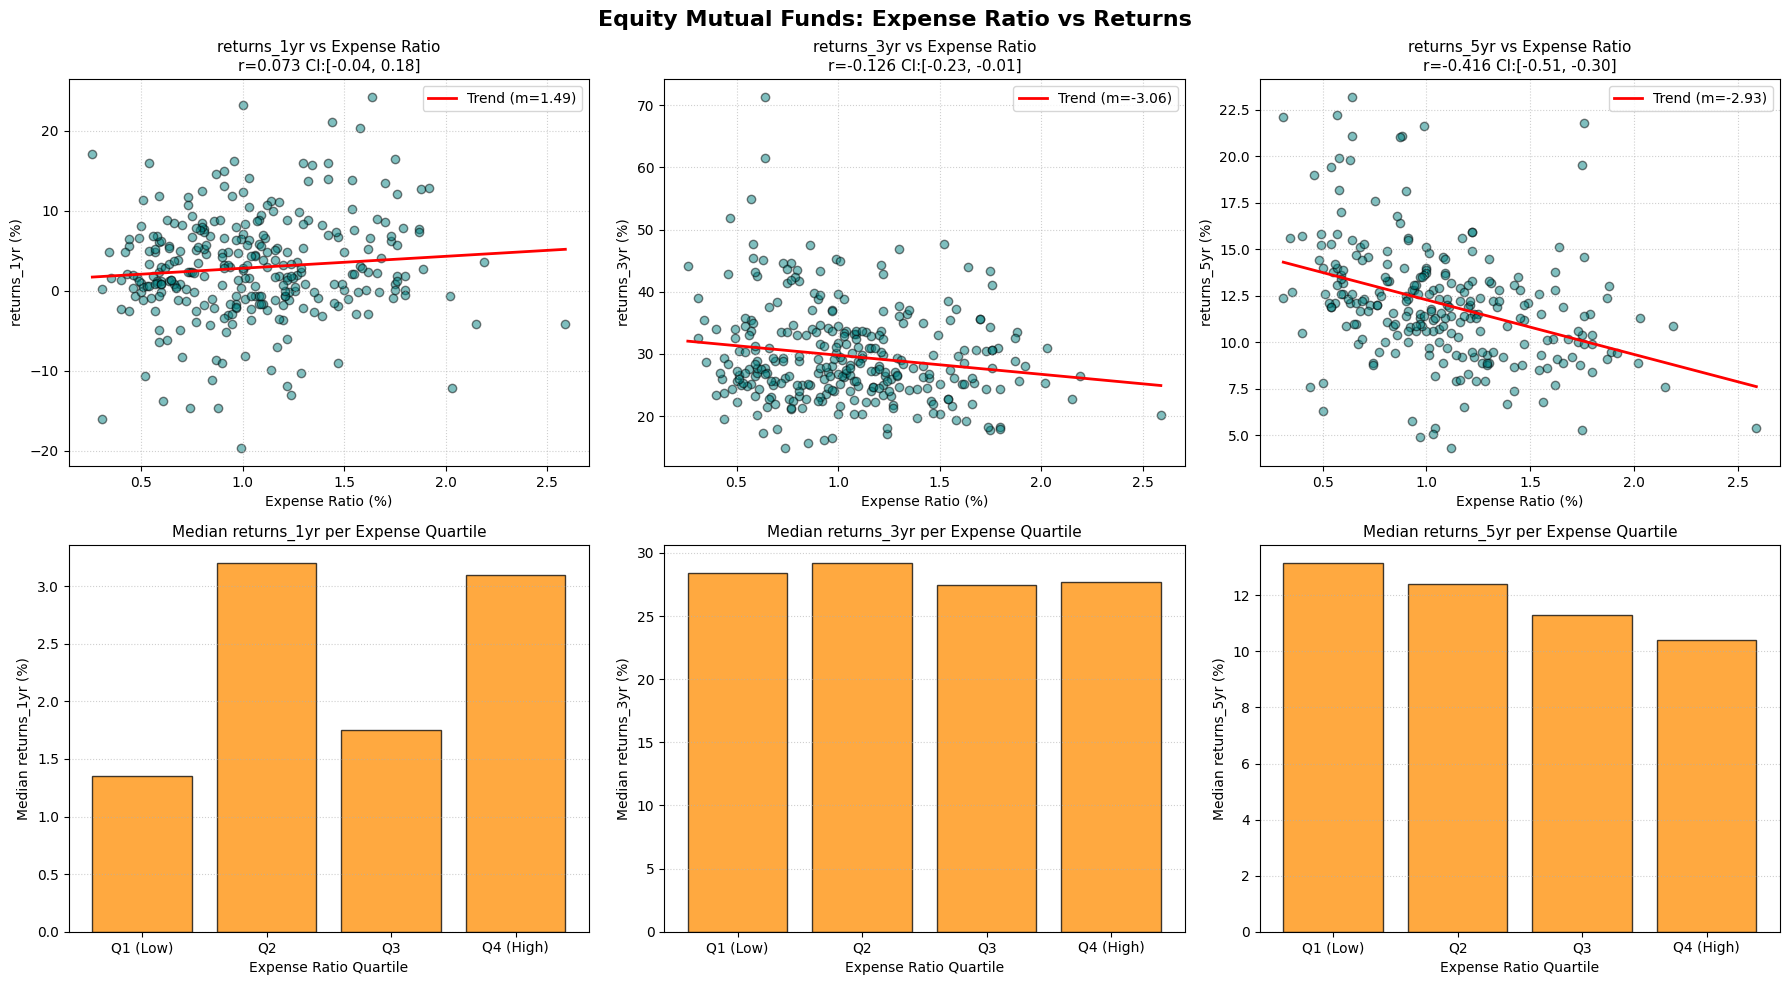


=== Analyzing Category: Debt (Total Funds: 281) ===
  returns_1yr vs Expense Ratio -> Spearman r: -0.297 | 95% CI: [-0.421, -0.166]
  returns_3yr vs Expense Ratio -> Spearman r: 0.582 | 95% CI: [0.477, 0.676]
  returns_5yr vs Expense Ratio -> Spearman r: 0.283 | 95% CI: [0.136, 0.425]


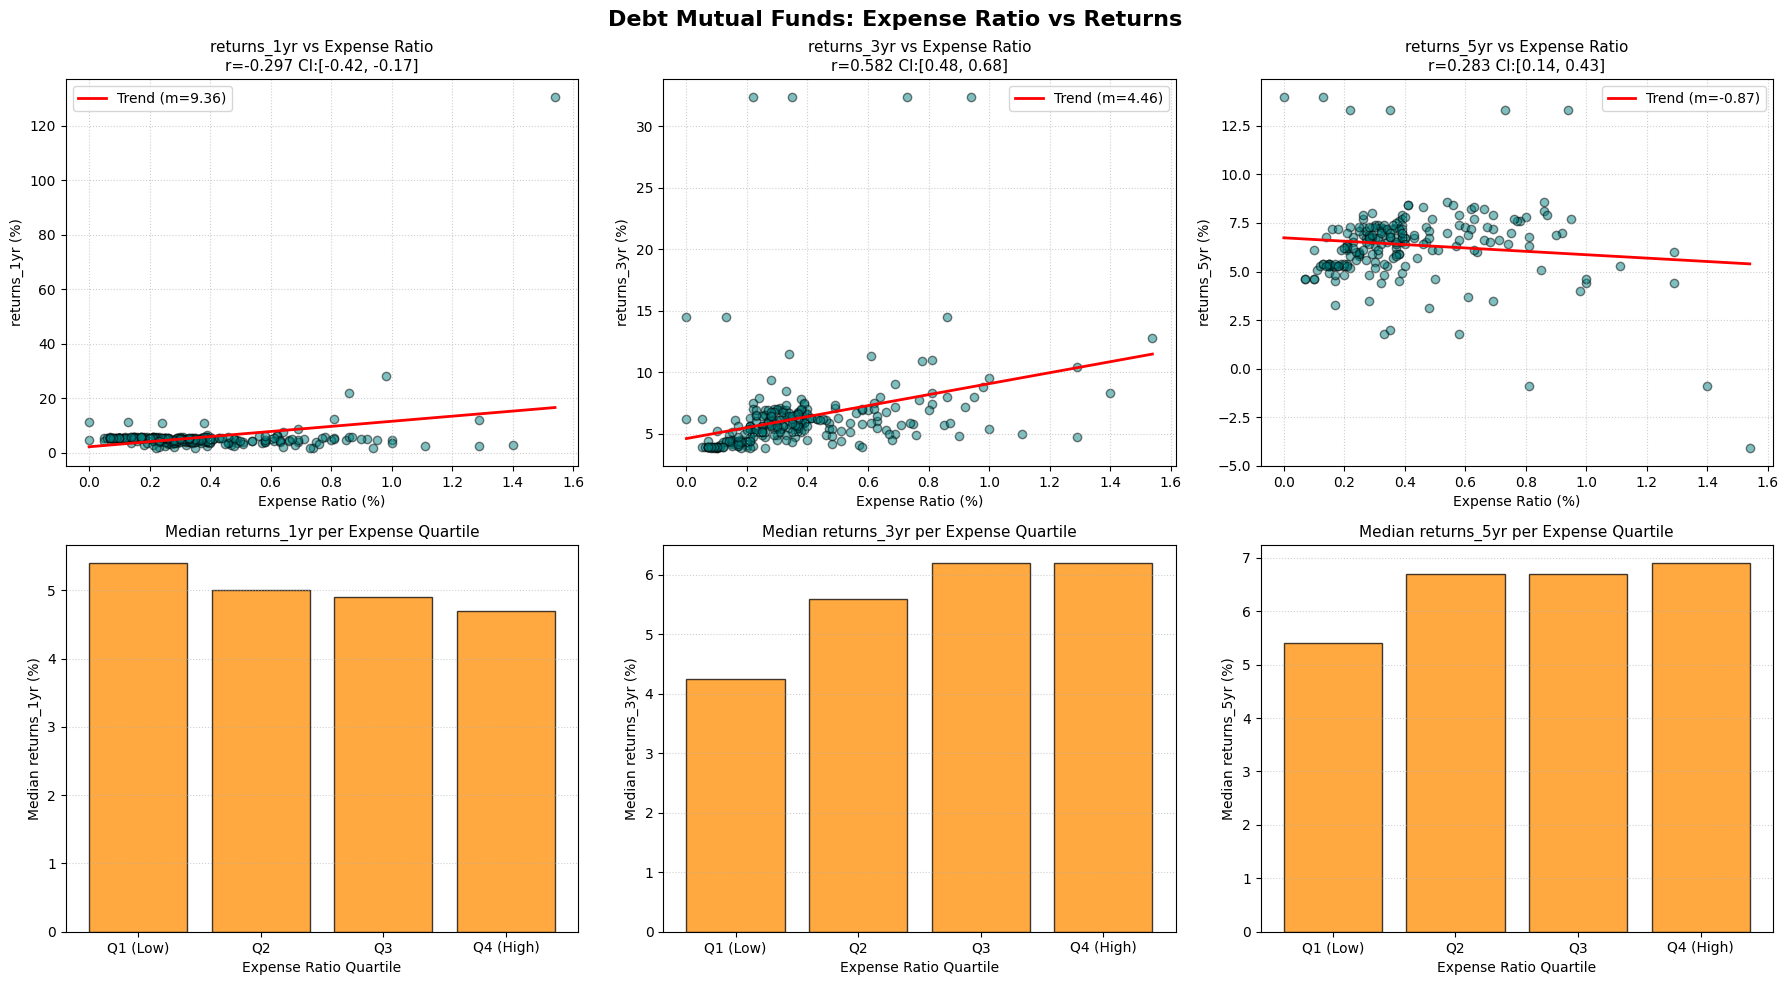


=== Analyzing Category: Hybrid (Total Funds: 116) ===
  returns_1yr vs Expense Ratio -> Spearman r: -0.189 | 95% CI: [-0.382, 0.017]
  returns_3yr vs Expense Ratio -> Spearman r: 0.346 | 95% CI: [0.154, 0.520]
  returns_5yr vs Expense Ratio -> Spearman r: 0.214 | 95% CI: [-0.015, 0.405]


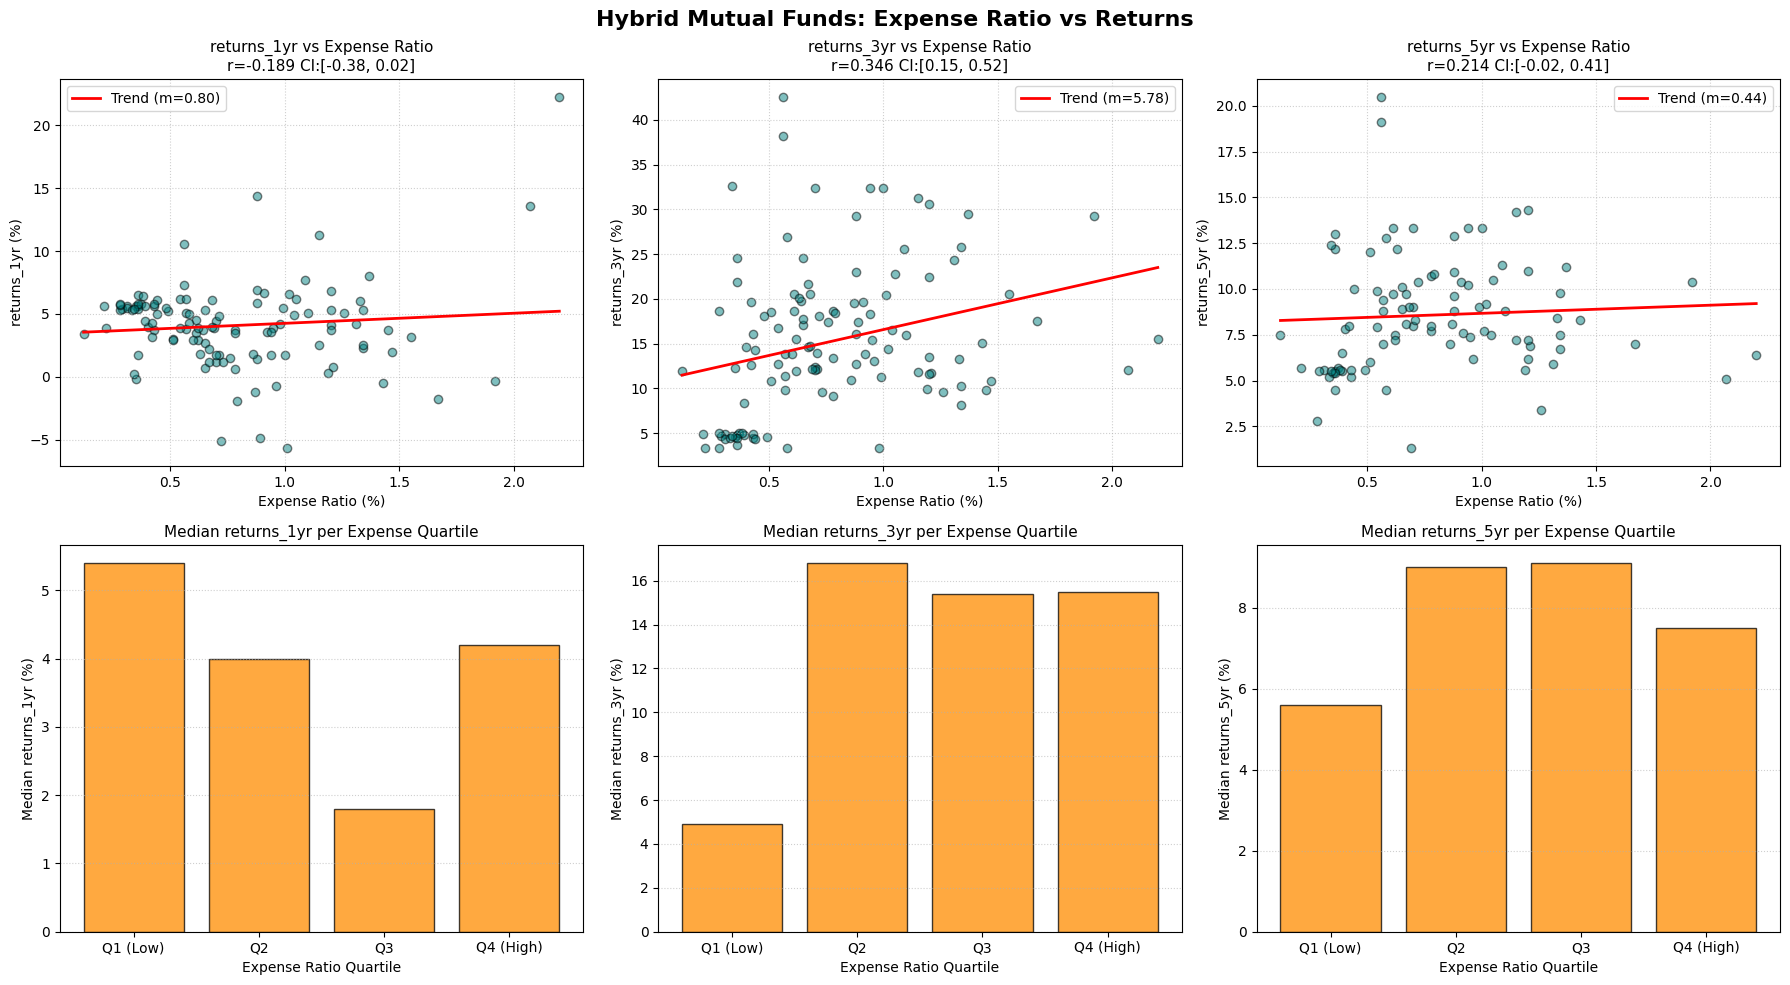

In [75]:
categories = ['Equity', 'Debt', 'Hybrid']
return_cols = ['returns_1yr', 'returns_3yr', 'returns_5yr']

for cat in categories:
    cat_df = df_clean[df_clean['category'] == cat].copy()
    print(f"\n=== Analyzing Category: {cat} (Total Funds: {len(cat_df)}) ===")

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle(f"{cat} Mutual Funds: Expense Ratio vs Returns", fontsize=16, fontweight='bold')

    for idx, ret_col in enumerate(return_cols):
        valid_df = cat_df[['expense_ratio', ret_col]].dropna().copy()
        if len(valid_df) < 10:
            axes[0, idx].text(0.5, 0.5, "Insufficient Data", ha='center', va='center')
            axes[1, idx].text(0.5, 0.5, "Insufficient Data", ha='center', va='center')
            continue

        # Correlation & Bootstrap CI
        pe, lower, upper = bootstrap_spearman_ci(valid_df, 'expense_ratio', ret_col)
        print(f"  {ret_col} vs Expense Ratio -> Spearman r: {pe:.3f} | 95% CI: [{lower:.3f}, {upper:.3f}]")

        # Scatter Plot with Polyfit Trendline
        x = valid_df['expense_ratio'].values
        y = valid_df[ret_col].values
        axes[0, idx].scatter(x, y, alpha=0.5, color='teal', edgecolor='k')

        # Fit trendline using np.polyfit
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        axes[0, idx].plot(x_line, slope * x_line + intercept, color='red', linewidth=2, label=f'Trend (m={slope:.2f})')

        axes[0, idx].set_title(f"{ret_col} vs Expense Ratio\nr={pe:.3f} CI:[{lower:.2f}, {upper:.2f}]", fontsize=11)
        axes[0, idx].set_xlabel('Expense Ratio (%)')
        axes[0, idx].set_ylabel(f'{ret_col} (%)')
        axes[0, idx].legend()
        axes[0, idx].grid(True, linestyle=':', alpha=0.6)

        # Split Expense Ratio into Quartiles & Plot Median Returns
        try:
            valid_df['expense_quartile'] = pd.qcut(valid_df['expense_ratio'], q=4, labels=['Q1 (Low)', 'Q2', 'Q3', 'Q4 (High)'])
            median_returns = valid_df.groupby('expense_quartile', observed=False)[ret_col].median()

            axes[1, idx].bar(median_returns.index.astype(str), median_returns.values, color='darkorange', edgecolor='black', alpha=0.75)
            axes[1, idx].set_title(f"Median {ret_col} per Expense Quartile", fontsize=11)
            axes[1, idx].set_xlabel('Expense Ratio Quartile')
            axes[1, idx].set_ylabel(f'Median {ret_col} (%)')
            axes[1, idx].grid(axis='y', linestyle=':', alpha=0.6)
        except Exception as e:
            axes[1, idx].text(0.5, 0.5, f"Error: {str(e)}", ha='center', va='center')

    plt.tight_layout()
    plt.show()

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Clean the rating column and prepare the dataset
df_rating = df_clean.copy()
# Ensure rating is treated as a numeric value, drop missing ratings or any invalid entries
df_rating['rating'] = pd.to_numeric(df_rating['rating'], errors='coerce')

# Numeric features for our analysis
features_to_clean = ['returns_3yr', 'sharpe', 'alpha', 'expense_ratio', 'sd', 'fund_size_cr']
for col in features_to_clean:
    df_rating[col] = pd.to_numeric(df_rating[col], errors='coerce')

# Drop rows where rating or any of the key features are null to ensure alignment
df_rating = df_rating.dropna(subset=['rating'] + features_to_clean).copy()
df_rating['rating'] = df_rating['rating'].astype(int)

print(f"Total funds with valid ratings and features: {len(df_rating)}")
print("Distribution of Ratings:")
print(df_rating['rating'].value_counts().sort_index())

Total funds with valid ratings and features: 745
Distribution of Ratings:
rating
0     75
1     54
2    155
3    230
4    155
5     76
Name: count, dtype: int64


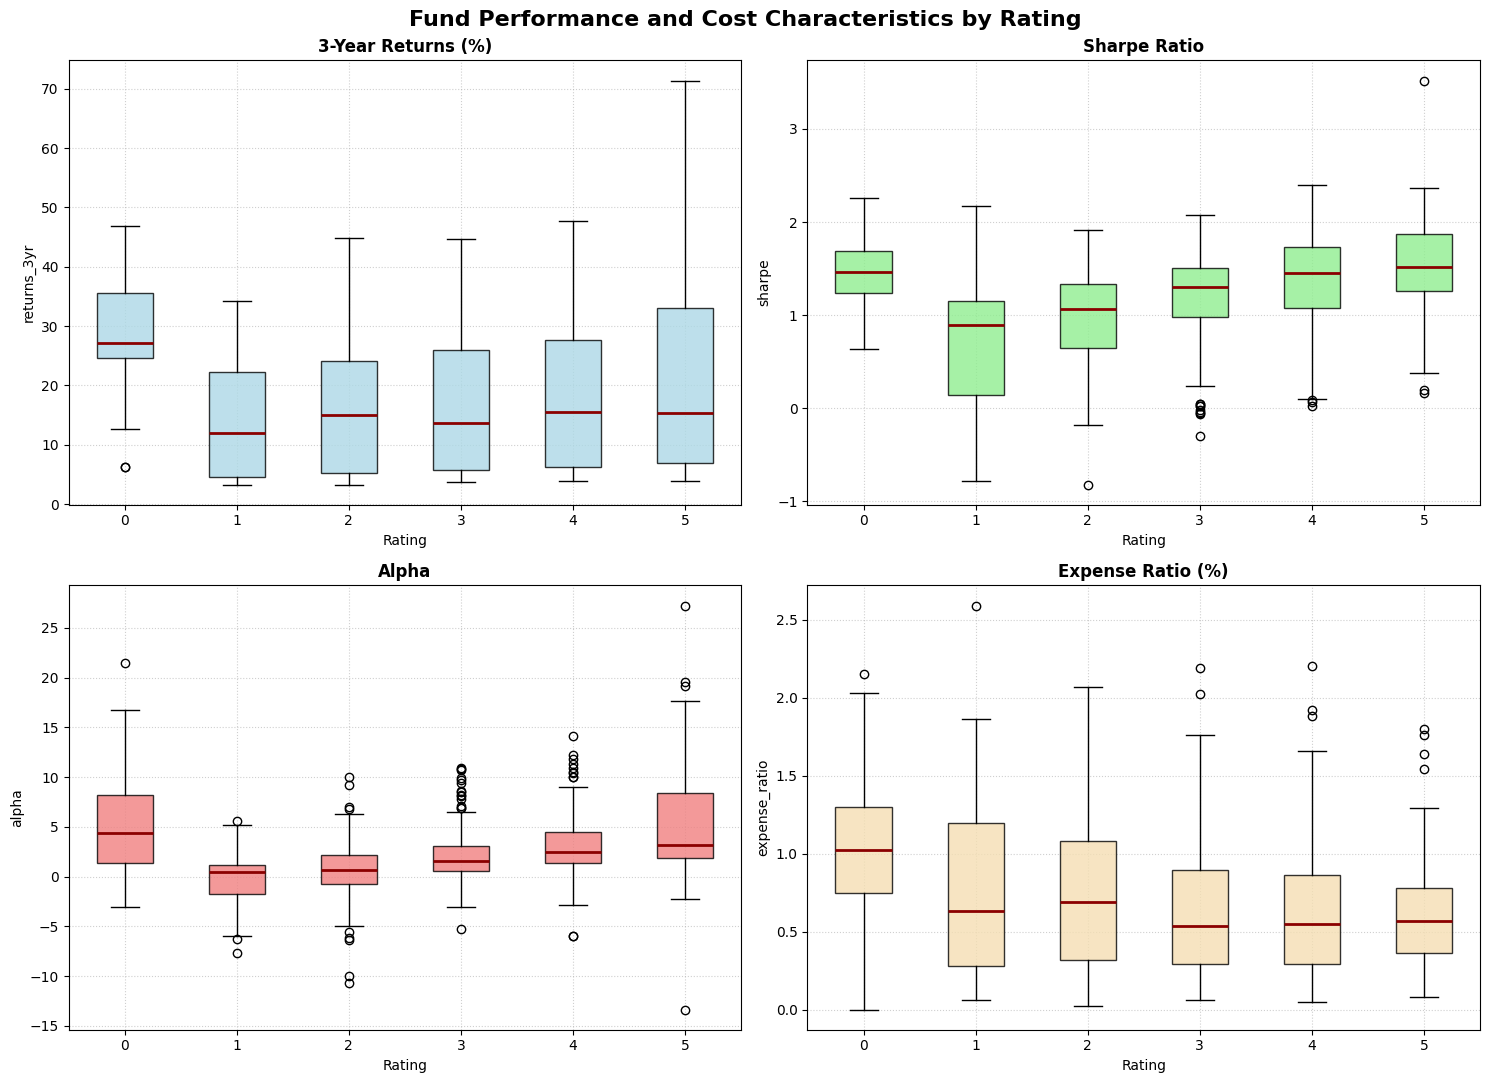

In [77]:
# 2. Plot boxplots of returns_3yr, sharpe, alpha, and expense_ratio grouped by rating
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle('Fund Performance and Cost Characteristics by Rating', fontsize=16, fontweight='bold')

metrics = ['returns_3yr', 'sharpe', 'alpha', 'expense_ratio']
titles = ['3-Year Returns (%)', 'Sharpe Ratio', 'Alpha', 'Expense Ratio (%)']
colors = ['lightblue', 'lightgreen', 'lightcoral', 'wheat']

ratings_sorted = sorted(df_rating['rating'].unique())

for idx, metric in enumerate(metrics):
    ax = axes[idx // 2, idx % 2]
    groups = [df_rating[df_rating['rating'] == r][metric].values for r in ratings_sorted]

    # Using tick_labels (Matplotlib 3.9+) or labels depending on support, using tick_labels as default standard
    ax.boxplot(groups, tick_labels=ratings_sorted, patch_artist=True,
               boxprops=dict(facecolor=colors[idx], color='black', alpha=0.8),
               medianprops=dict(color='darkred', linewidth=2))

    ax.set_title(titles[idx], fontsize=12, fontweight='bold')
    ax.set_xlabel('Rating')
    ax.set_ylabel(metric)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [78]:
# 3. Pairwise Median Differences with Bootstrap Confidence Intervals (No Scipy)
def bootstrap_median_diff(data1, data2, num_resamples=1000, alpha=0.05, seed=42):
    rng = np.random.default_rng(seed)
    n1, n2 = len(data1), len(data2)
    if n1 == 0 or n2 == 0:
        return np.nan, np.nan, np.nan

    obs_diff = np.median(data1) - np.median(data2)
    boot_diffs = []

    for _ in range(num_resamples):
        boot1 = rng.choice(data1, size=n1, replace=True)
        boot2 = rng.choice(data2, size=n2, replace=True)
        boot_diffs.append(np.median(boot1) - np.median(boot2))

    boot_diffs = np.array(boot_diffs)
    lower = np.percentile(boot_diffs, (alpha / 2) * 100)
    upper = np.percentile(boot_diffs, (1 - alpha / 2) * 100)
    return obs_diff, lower, upper

# We check adjacent ratings (e.g., 5 vs 4, 4 vs 3, etc.) for each key metric
print("=== Adjacent Rating Group Median Differences (Rating A vs Rating B) with 95% Bootstrap CI ===\n")
for metric in metrics:
    print(f"--- Metric: {metric} ---")
    for r_high in range(5, 0, -1):
        r_low = r_high - 1
        data_high = df_rating[df_rating['rating'] == r_high][metric].values
        data_low = df_rating[df_rating['rating'] == r_low][metric].values

        if len(data_high) >= 5 and len(data_low) >= 5:
            diff, ci_l, ci_u = bootstrap_median_diff(data_high, data_low)
            print(f"  Rating {r_high} vs {r_low} | Median Diff: {diff:+.3f} | 95% CI: [{ci_l:+.3f}, {ci_u:+.3f}]")
    print()

=== Adjacent Rating Group Median Differences (Rating A vs Rating B) with 95% Bootstrap CI ===

--- Metric: returns_3yr ---
  Rating 5 vs 4 | Median Diff: -0.200 | 95% CI: [-8.101, +15.802]
  Rating 4 vs 3 | Median Diff: +1.800 | 95% CI: [-8.300, +8.704]
  Rating 3 vs 2 | Median Diff: -1.300 | 95% CI: [-6.250, +6.900]
  Rating 2 vs 1 | Median Diff: +3.050 | 95% CI: [-5.303, +10.811]
  Rating 1 vs 0 | Median Diff: -15.150 | 95% CI: [-22.554, -7.699]

--- Metric: sharpe ---
  Rating 5 vs 4 | Median Diff: +0.070 | 95% CI: [-0.020, +0.215]
  Rating 4 vs 3 | Median Diff: +0.150 | 95% CI: [+0.040, +0.200]
  Rating 3 vs 2 | Median Diff: +0.230 | 95% CI: [+0.135, +0.380]
  Rating 2 vs 1 | Median Diff: +0.180 | 95% CI: [+0.000, +0.655]
  Rating 1 vs 0 | Median Diff: -0.570 | 95% CI: [-1.046, -0.425]

--- Metric: alpha ---
  Rating 5 vs 4 | Median Diff: +0.715 | 95% CI: [+0.090, +2.490]
  Rating 4 vs 3 | Median Diff: +0.870 | 95% CI: [+0.470, +1.260]
  Rating 3 vs 2 | Median Diff: +0.900 | 95% CI

Regression Coefficients:
  sharpe: +0.4563
  alpha: +0.1241
  expense_ratio: -0.3023
  sd: +0.0541
  returns_3yr: -0.3530
  fund_size_cr: +0.1547
  intercept: 2.7570


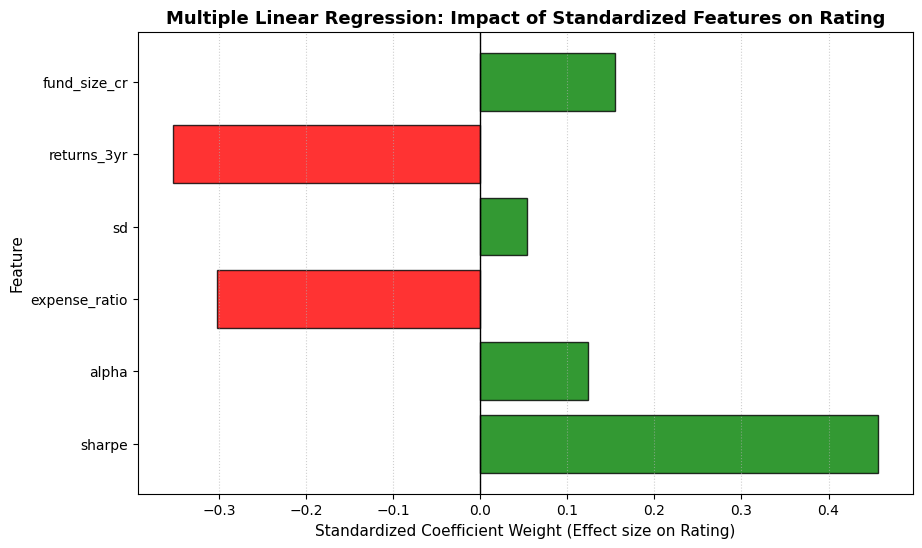

In [79]:
# 4. Multiple Linear Regression of Rating on Standardized Features using np.linalg.lstsq
reg_features = ['sharpe', 'alpha', 'expense_ratio', 'sd', 'returns_3yr', 'fund_size_cr']
X = df_rating[reg_features].copy()
y = df_rating['rating'].values

# Standardize features (mean=0, std=1) manually
X_scaled = (X - X.mean()) / X.std()

# Add intercept column to the design matrix
X_scaled['intercept'] = 1.0

# Solve normal equations: y = X_scaled * beta
# np.linalg.lstsq returns (coefficients, residuals, rank, singular_values)
beta, residuals, rank, s = np.linalg.lstsq(X_scaled.values, y, rcond=None)

# Map coefficients to feature names
coef_map = dict(zip(X_scaled.columns, beta))
print("Regression Coefficients:")
for feat in reg_features:
    print(f"  {feat}: {coef_map[feat]:+.4f}")
print(f"  intercept: {coef_map['intercept']:.4f}")

# 5. Plot the standardized coefficients in a horizontal bar chart
plt.figure(figsize=(10, 6))
coef_values = [coef_map[f] for f in reg_features]
plt.barh(reg_features, coef_values, color=['green' if val >= 0 else 'red' for val in coef_values], edgecolor='black', alpha=0.8)
plt.axvline(0, color='black', linestyle='-', linewidth=1)
plt.title('Multiple Linear Regression: Impact of Standardized Features on Rating', fontsize=13, fontweight='bold')
plt.xlabel('Standardized Coefficient Weight (Effect size on Rating)', fontsize=11)
plt.ylabel('Feature', fontsize=11)
plt.grid(True, axis='x', linestyle=':', alpha=0.6)
plt.show()

In [80]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare and standardize features
cluster_cols = ['sd', 'sharpe', 'alpha', 'beta', 'expense_ratio', 'returns_3yr']

# Filter for records that have all valid features required
df_cluster = df_clean.dropna(subset=cluster_cols + ['sub_category']).copy()
X_raw = df_cluster[cluster_cols].values

# Standardize manual scaling: (X - mean) / std
X_mean = np.mean(X_raw, axis=0)
X_std = np.std(X_raw, axis=0)
X_scaled = (X_raw - X_mean) / X_std

print(f"Data points scaled for clustering: {X_scaled.shape[0]}")

Data points scaled for clustering: 745


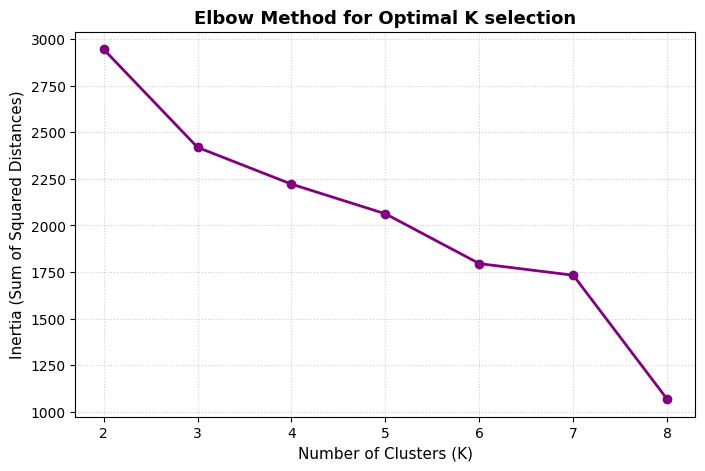

In [81]:
# 2. Implement K-Means from scratch
class KMeansScratch:
    def __init__(self, k, max_iters=100, tol=1e-4, seed=42):
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.seed = seed
        self.centroids = None
        self.labels = None
        self.inertia_ = None

    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        n_samples = X.shape[0]

        # Randomly choose initial centroids
        random_indices = rng.choice(n_samples, size=self.k, replace=False)
        self.centroids = X[random_indices].copy()

        for _ in range(self.max_iters):
            # E-step: Assign each point to nearest centroid
            distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
            self.labels = np.argmin(distances, axis=1)

            # M-step: Update centroids
            new_centroids = np.zeros_like(self.centroids)
            for j in range(self.k):
                cluster_points = X[self.labels == j]
                if len(cluster_points) > 0:
                    new_centroids[j] = np.mean(cluster_points, axis=0)
                else:
                    new_centroids[j] = self.centroids[j]

            # Check for convergence
            if np.all(np.linalg.norm(new_centroids - self.centroids, axis=1) < self.tol):
                self.centroids = new_centroids
                break
            self.centroids = new_centroids

        # Compute inertia
        distances = np.linalg.norm(X[:, np.newaxis] - self.centroids, axis=2)
        min_distances = np.min(distances, axis=1)
        self.inertia_ = np.sum(min_distances ** 2)
        return self

# 3. Determine optimal K using elbow plot (K = 2..8)
inertias = []
k_range = range(2, 9)
for k in k_range:
    km = KMeansScratch(k=k, seed=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_range), inertias, marker='o', color='purple', linestyle='-', linewidth=2)
plt.title('Elbow Method for Optimal K selection', fontsize=13, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=11)
plt.ylabel('Inertia (Sum of Squared Distances)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

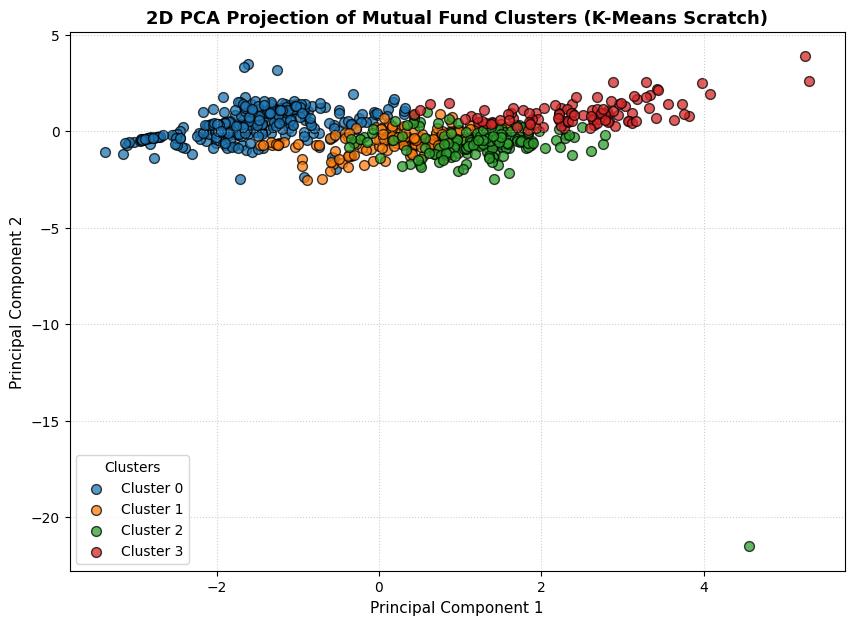

In [82]:
# Based on the elbow plot, let's select a representative number of clusters (typically K=4 or K=5)
# Let's run with K=4 for optimal differentiation of fund characteristics.
K_optimal = 4
km_final = KMeansScratch(k=K_optimal, seed=42)
km_final.fit(X_scaled)
df_cluster['cluster'] = km_final.labels

# 4. Dimension Reduction with PCA using SVD
# Center the standardized matrix (it's already standardized, but centering ensures no small float deviations)
X_centered = X_scaled - np.mean(X_scaled, axis=0)
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)

# Project onto first two principal components
X_pca = np.dot(X_centered, Vt.T[:, :2])

# Scatter plot visualization of clusters
plt.figure(figsize=(10, 7))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

for cluster_id in range(K_optimal):
    cluster_data = X_pca[df_cluster['cluster'] == cluster_id]
    plt.scatter(cluster_data[:, 0], cluster_data[:, 1],
                color=colors[cluster_id], label=f'Cluster {cluster_id}',
                alpha=0.75, edgecolor='black', s=50)

plt.title('2D PCA Projection of Mutual Fund Clusters (K-Means Scratch)', fontsize=13, fontweight='bold')
plt.xlabel('Principal Component 1', fontsize=11)
plt.ylabel('Principal Component 2', fontsize=11)
plt.legend(title='Clusters', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [83]:
# 5. Profile each cluster with means of key metrics and dominant sub-categories
cluster_profiles = []

print("=== Cluster Profiling Analysis ===\n")
for cluster_id in range(K_optimal):
    subset = df_cluster[df_cluster['cluster'] == cluster_id]
    size = len(subset)

    # Average metrics
    means = subset[cluster_cols].mean()

    # Determine dominant sub-category
    dominant_sub = subset['sub_category'].value_counts().index[0] if size > 0 else "N/A"
    dominant_sub_pct = (subset['sub_category'].value_counts().values[0] / size * 100) if size > 0 else 0.0

    print(f"--- Cluster {cluster_id} (Size: {size} funds) ---")
    print(f"  Mean Returns (3-Year): {means['returns_3yr']:.2f}%")
    print(f"  Mean Sharpe Ratio:    {means['sharpe']:.2f}")
    print(f"  Mean Alpha:           {means['alpha']:.2f}")
    print(f"  Mean Beta:            {means['beta']:.2f}")
    print(f"  Mean Standard Dev:     {means['sd']:.2f}%")
    print(f"  Mean Expense Ratio:   {means['expense_ratio']:.2f}%")
    print(f"  Dominant Sub-Category: {dominant_sub} ({dominant_sub_pct:.1f}% of cluster)")
    print()

    cluster_profiles.append({
        'cluster': cluster_id,
        'size': size,
        'returns_3yr': means['returns_3yr'],
        'sharpe': means['sharpe'],
        'dominant_sub': dominant_sub
    })

=== Cluster Profiling Analysis ===

--- Cluster 0 (Size: 313 funds) ---
  Mean Returns (3-Year): 6.46%
  Mean Sharpe Ratio:    0.93
  Mean Alpha:           2.16
  Mean Beta:            0.88
  Mean Standard Dev:     2.08%
  Mean Expense Ratio:   0.38%
  Dominant Sub-Category: Liquid Mutual Funds (10.5% of cluster)

--- Cluster 1 (Size: 164 funds) ---
  Mean Returns (3-Year): 22.66%
  Mean Sharpe Ratio:    1.23
  Mean Alpha:           -0.32
  Mean Beta:            0.87
  Mean Standard Dev:     14.69%
  Mean Expense Ratio:   0.58%
  Dominant Sub-Category: Index Funds (17.1% of cluster)

--- Cluster 2 (Size: 167 funds) ---
  Mean Returns (3-Year): 24.48%
  Mean Sharpe Ratio:    1.35
  Mean Alpha:           1.66
  Mean Beta:            0.65
  Mean Standard Dev:     15.55%
  Mean Expense Ratio:   1.33%
  Dominant Sub-Category: Sectoral / Thematic Mutual Funds (25.1% of cluster)

--- Cluster 3 (Size: 101 funds) ---
  Mean Returns (3-Year): 37.21%
  Mean Sharpe Ratio:    1.79
  Mean Alpha:    

In [84]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure we have clean columns
df_size = df_clean.copy()
df_size['fund_size_cr'] = pd.to_numeric(df_size['fund_size_cr'], errors='coerce')
df_size['alpha'] = pd.to_numeric(df_size['alpha'], errors='coerce')
df_size['returns_3yr'] = pd.to_numeric(df_size['returns_3yr'], errors='coerce')

# Drop rows missing crucial size or performance indicators
df_size = df_size.dropna(subset=['fund_size_cr', 'alpha', 'returns_3yr', 'category']).copy()

# Avoid log10 errors by ensuring size > 0
df_size = df_size[df_size['fund_size_cr'] > 0].copy()

# Calculate log10 size
df_size['log_fund_size'] = np.log10(df_size['fund_size_cr'])

# Bin into 5 equal-frequency buckets
df_size['size_bucket'] = pd.qcut(df_size['log_fund_size'], q=5, labels=['S1 (XS)', 'S2 (S)', 'S3 (M)', 'S4 (L)', 'S5 (XL)'])

# Display the range of each bucket
bucket_ranges = df_size.groupby('size_bucket', observed=False)['fund_size_cr'].agg(['min', 'max', 'count'])
print("=== Fund Size Buckets (Crores) ===")
display(bucket_ranges)

=== Fund Size Buckets (Crores) ===


,min,max,count
size_bucket,,,
S1 (XS),2.38,152.0,150
S2 (S),153.00,601.0,149
S3 (M),606.00,1795.0,150
S4 (L),1797.00,6396.0,148
S5 (XL),6434.00,57052.0,149


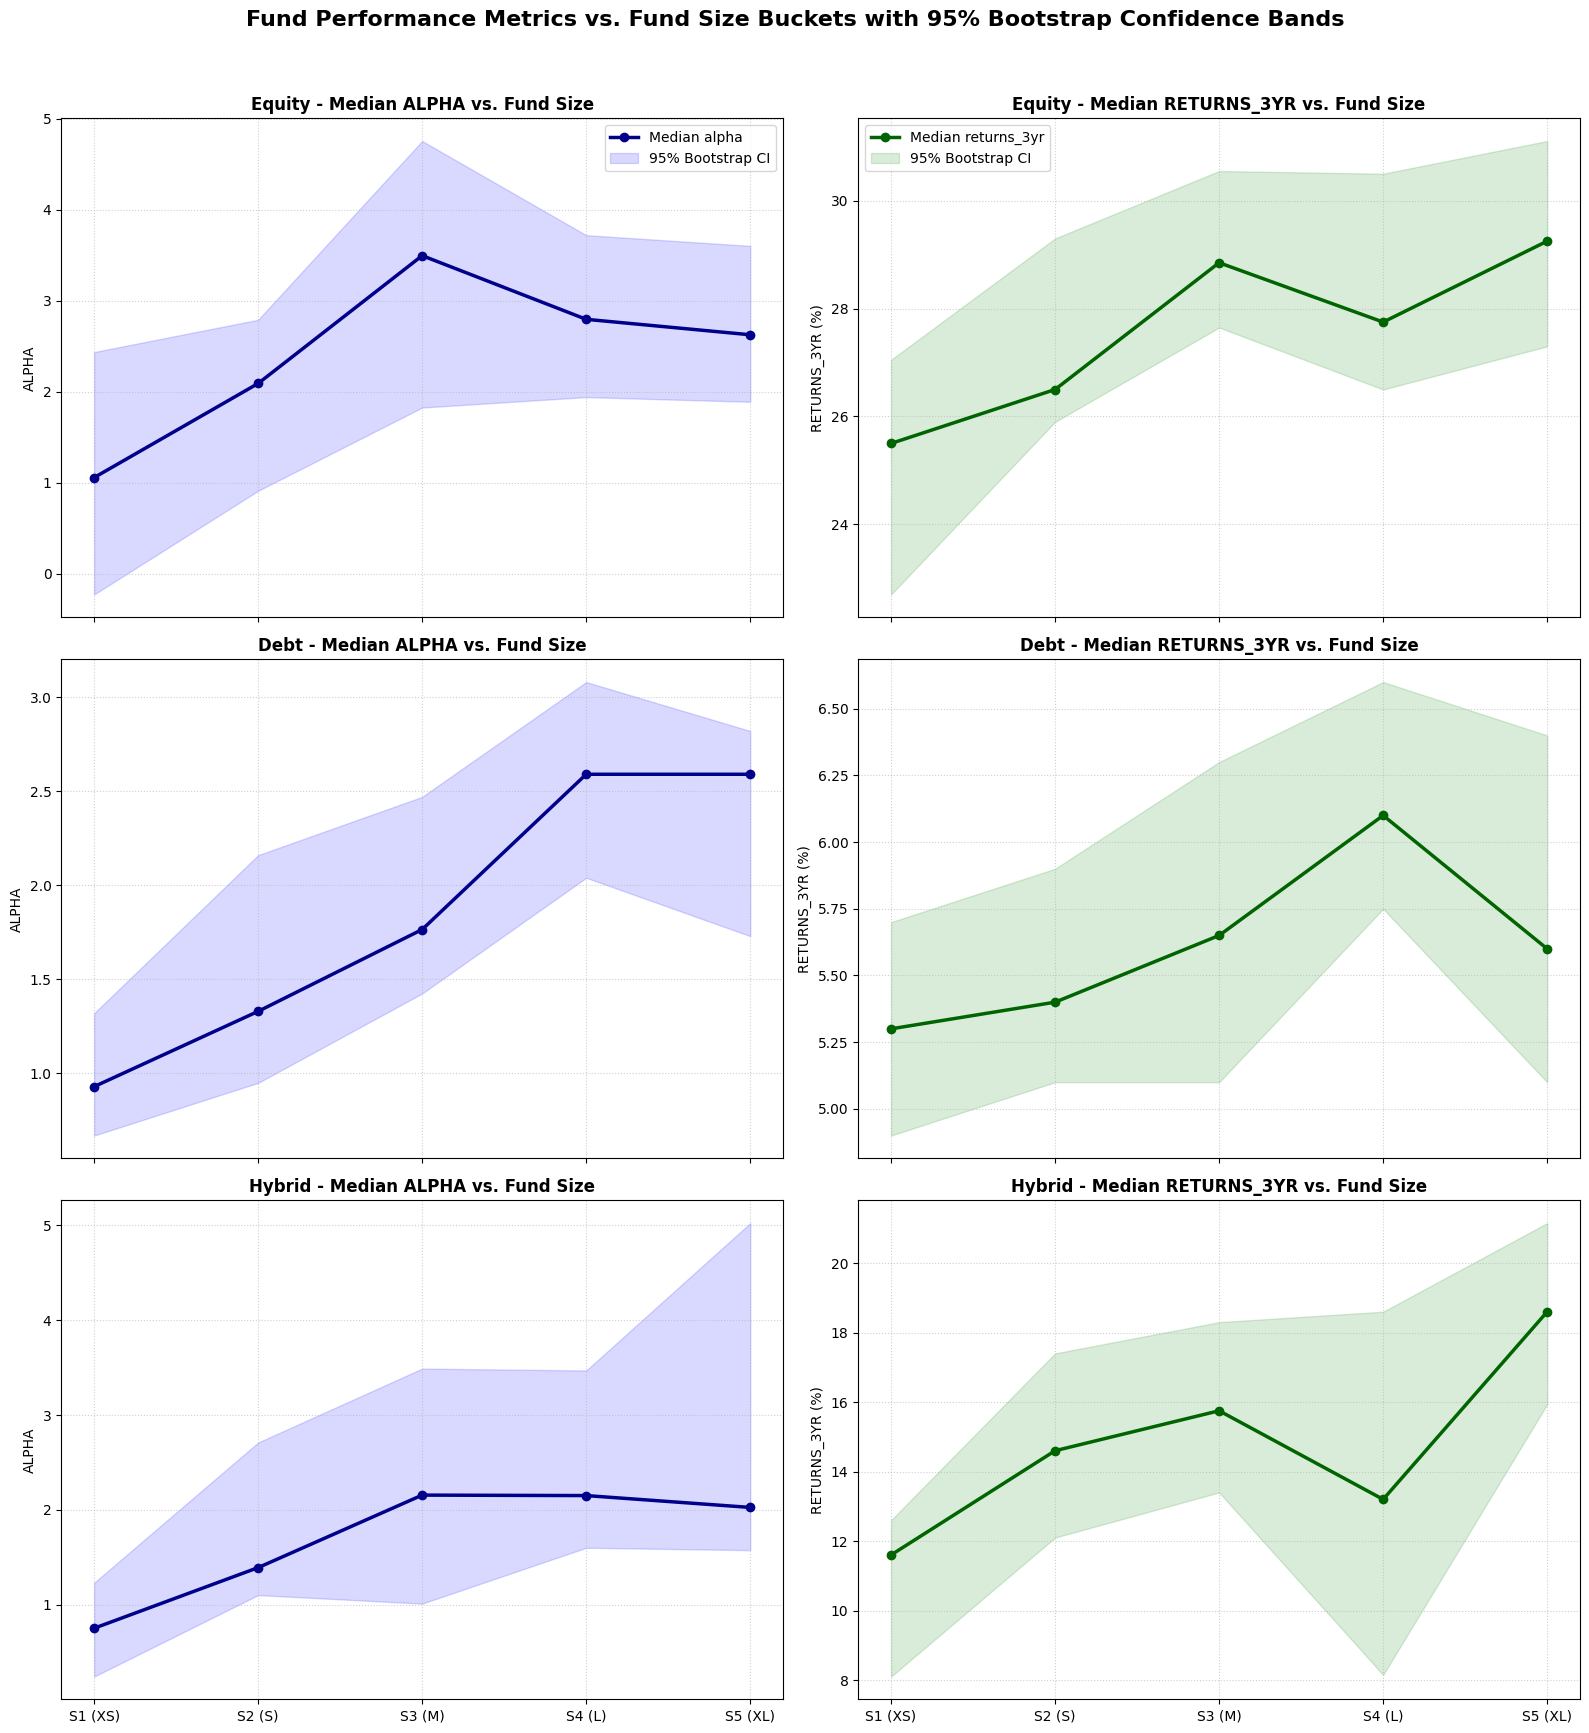

In [85]:
def bootstrap_median_ci(data, num_resamples=1000, alpha=0.05, seed=42):
    if len(data) == 0:
        return np.nan, np.nan, np.nan
    rng = np.random.default_rng(seed)
    observed_median = np.median(data)

    boot_medians = []
    n = len(data)
    for _ in range(num_resamples):
        sample = rng.choice(data, size=n, replace=True)
        boot_medians.append(np.median(sample))

    boot_medians = np.array(boot_medians)
    lower = np.percentile(boot_medians, (alpha / 2) * 100)
    upper = np.percentile(boot_medians, (1 - alpha / 2) * 100)
    return observed_median, lower, upper

categories = ['Equity', 'Debt', 'Hybrid']
buckets = ['S1 (XS)', 'S2 (S)', 'S3 (M)', 'S4 (L)', 'S5 (XL)']

# Prepare subplot figure
fig, axes = plt.subplots(3, 2, figsize=(16, 18), sharex=True)
fig.suptitle('Fund Performance Metrics vs. Fund Size Buckets with 95% Bootstrap Confidence Bands', fontsize=16, fontweight='bold', y=0.96)

for cat_idx, cat in enumerate(categories):
    cat_df = df_size[df_size['category'] == cat]

    for metric_idx, metric in enumerate(['alpha', 'returns_3yr']):
        ax = axes[cat_idx, metric_idx]
        medians, lowers, uppers = [], [], []

        for bucket in buckets:
            bucket_data = cat_df[cat_df['size_bucket'] == bucket][metric].dropna().values
            med, low, upp = bootstrap_median_ci(bucket_data)
            medians.append(med)
            lowers.append(low)
            uppers.append(upp)

        # Plot line chart
        ax.plot(buckets, medians, marker='o', linewidth=2.5, color='darkblue' if metric == 'alpha' else 'darkgreen', label=f'Median {metric}')
        # Plot bootstrap confidence band
        ax.fill_between(buckets, lowers, uppers, color='blue' if metric == 'alpha' else 'green', alpha=0.15, label='95% Bootstrap CI')

        ax.set_title(f"{cat} - Median {metric.upper()} vs. Fund Size", fontsize=12, fontweight='bold')
        ax.set_ylabel(metric.upper() + ' (%)' if metric == 'returns_3yr' else metric.upper())
        ax.grid(True, linestyle=':', alpha=0.6)
        if cat_idx == 0:
            ax.legend(loc='best')

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare data and clean fields
df_amc = df_clean.copy()
dec_cols = ['rating', 'alpha', 'sharpe', 'expense_ratio', 'returns_3yr', 'fund_size_cr']
for col in dec_cols:
    df_amc[col] = pd.to_numeric(df_amc[col], errors='coerce')

# Calculate sub-category medians for 3-year returns to find funds that outperform their peers
subcat_medians = df_amc.groupby('sub_category')['returns_3yr'].transform('median')
df_amc['beats_subcat_median'] = df_amc['returns_3yr'] > subcat_medians

# Group by AMC to filter those with >= 8 funds
amc_counts = df_amc['amc_name'].value_counts()
eligible_amcs = amc_counts[amc_counts >= 8].index
df_eligible = df_amc[df_amc['amc_name'].isin(eligible_amcs)].copy()

# Build the scorecard metrics per AMC
amc_scorecard = df_eligible.groupby('amc_name').agg(
    mean_rating=('rating', 'mean'),
    median_alpha=('alpha', 'median'),
    median_sharpe=('sharpe', 'median'),
    mean_expense_ratio=('expense_ratio', 'mean'),
    pct_beating_peers=('beats_subcat_median', lambda x: x.mean() * 100),
    total_aum_cr=('fund_size_cr', 'sum'),
    fund_count=('amc_name', 'count')
).dropna() # drop any AMC with null in key aggregates if any

display(amc_scorecard.round(3).sort_values(by='mean_rating', ascending=False))

,mean_rating,median_alpha,median_sharpe,mean_expense_ratio,pct_beating_peers,total_aum_cr,fund_count
amc_name,,,,,,,
Quant Mutual Fund,4.545,15.930,1.950,0.562,100.000,17106.00,11
Mirae Asset Mutual Fund,3.389,2.615,1.445,0.401,44.444,107063.00,18
Canara Robeco Mutual Fund,3.389,1.655,1.235,0.555,22.222,57929.00,18
Bank of India Mutual Fund,3.286,2.595,1.000,1.259,57.143,2813.00,14
Mahindra Manulife Mutual Fund,3.143,2.380,1.560,0.501,50.000,6991.00,14
Kotak Mahindra Mutual Fund,3.125,2.745,1.435,0.479,71.875,255952.00,32
Axis Mutual Fund,3.121,1.190,1.110,0.460,33.333,220489.00,33
JM Financial Mutual Fund,3.091,1.220,1.080,1.059,36.364,2284.00,11
Baroda BNP Paribas Mutual Fund,3.042,1.310,1.120,0.638,16.667,19782.00,24


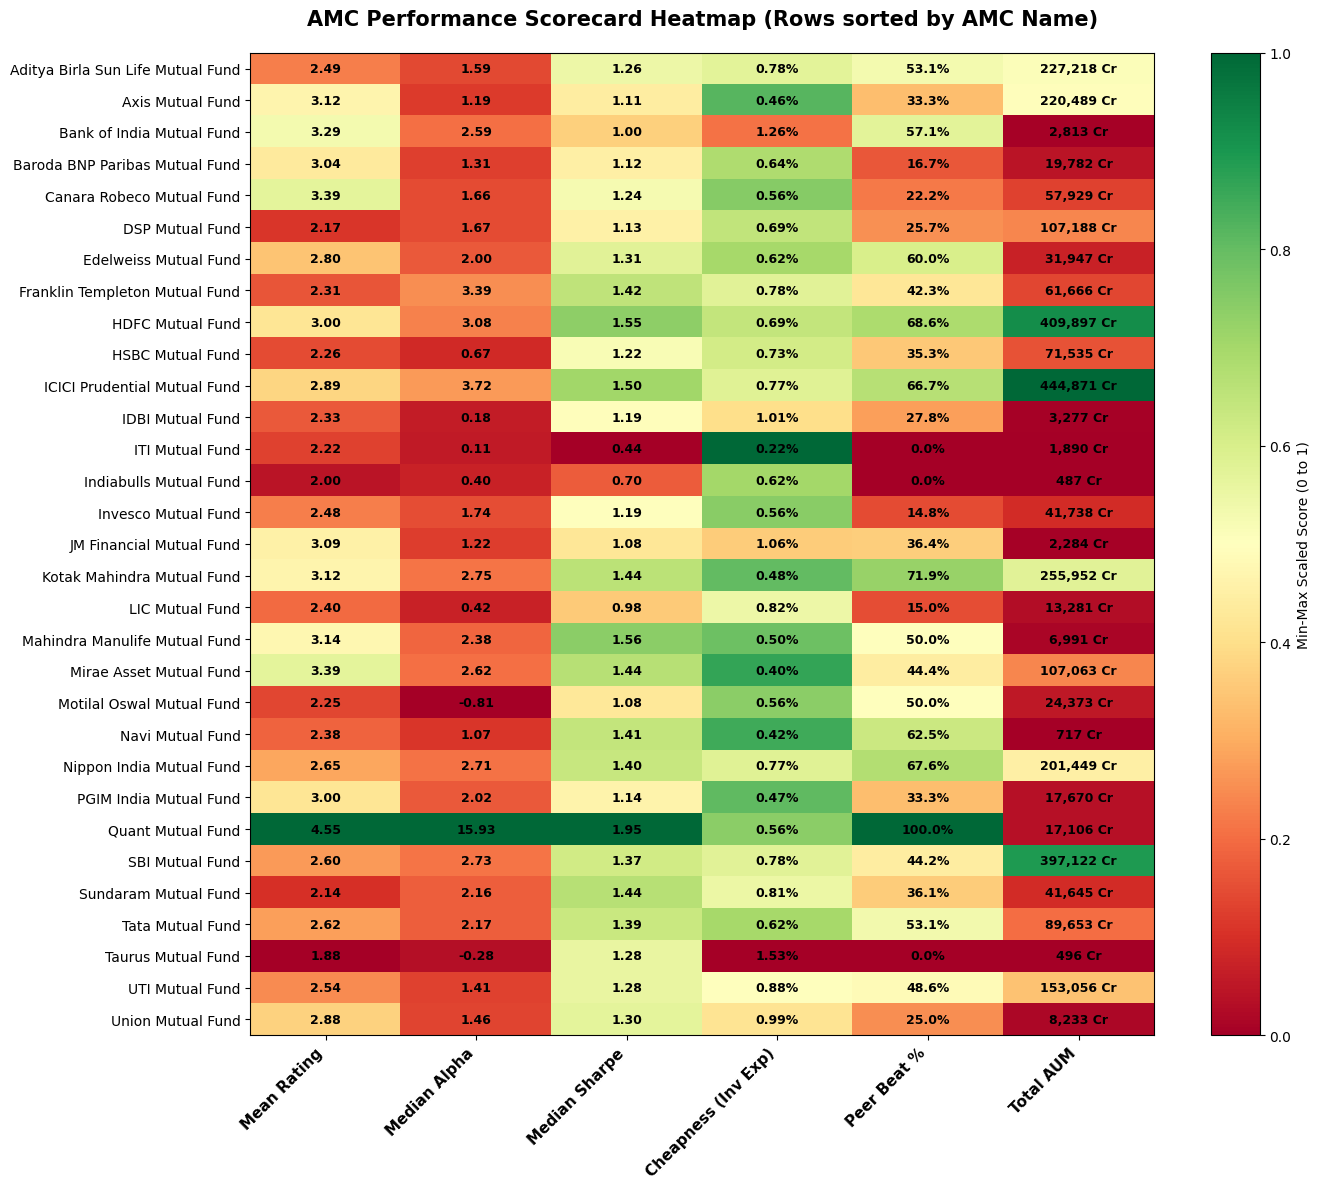

In [87]:
# 2. Scale each column (Min-Max) for the heatmap representation
# Note: For expense ratio, lower is better. However, to make all columns consistent (higher value is "better" or "more positive"),
# we will scale it as 1 - normalized_expense_ratio, so higher scores indicate cheaper/better fees.

heatmap_metrics = ['mean_rating', 'median_alpha', 'median_sharpe', 'mean_expense_ratio', 'pct_beating_peers', 'total_aum_cr']
amc_scaled = amc_scorecard[heatmap_metrics].copy()

# Apply min-max scaling column-by-column
for col in heatmap_metrics:
    col_min = amc_scaled[col].min()
    col_max = amc_scaled[col].max()
    if col_max > col_min:
        if col == 'mean_expense_ratio':
            # Reverse scaling: higher score = cheaper/lower expenses
            amc_scaled[col] = 1.0 - ((amc_scaled[col] - col_min) / (col_max - col_min))
        else:
            amc_scaled[col] = (amc_scaled[col] - col_min) / (col_max - col_min)
    else:
        amc_scaled[col] = 1.0

# Plot the Heatmap using plt.imshow
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(amc_scaled.values, cmap='RdYlGn', aspect='auto')

# Set labels
ax.set_xticks(np.arange(len(heatmap_metrics)))
ax.set_yticks(np.arange(len(amc_scaled)))
# Custom labels replacing 'mean_expense_ratio' to show it's score-inverted
metric_labels = ['Mean Rating', 'Median Alpha', 'Median Sharpe', 'Cheapness (Inv Exp)', 'Peer Beat %', 'Total AUM']
ax.set_xticklabels(metric_labels, rotation=45, ha='right', fontsize=11, fontweight='bold')
ax.set_yticklabels(amc_scaled.index, fontsize=10)

# Loop over data dimensions and create text annotations
for i in range(len(amc_scaled)):
    for j in range(len(heatmap_metrics)):
        raw_val = amc_scorecard.iloc[i][heatmap_metrics[j]]
        # Custom formatting based on columns
        if heatmap_metrics[j] == 'total_aum_cr':
            label = f"{raw_val:,.0f} Cr"
        elif heatmap_metrics[j] in ['mean_rating', 'median_alpha', 'median_sharpe']:
            label = f"{raw_val:.2f}"
        elif heatmap_metrics[j] == 'pct_beating_peers':
            label = f"{raw_val:.1f}%"
        else:
            label = f"{raw_val:.2f}%"
        text = ax.text(j, i, label, ha="center", va="center", color="black", fontsize=9, fontweight='semibold')

ax.set_title("AMC Performance Scorecard Heatmap (Rows sorted by AMC Name)", fontsize=15, fontweight='bold', pad=20)
fig.tight_layout()
plt.colorbar(im, label='Min-Max Scaled Score (0 to 1)')
plt.show()

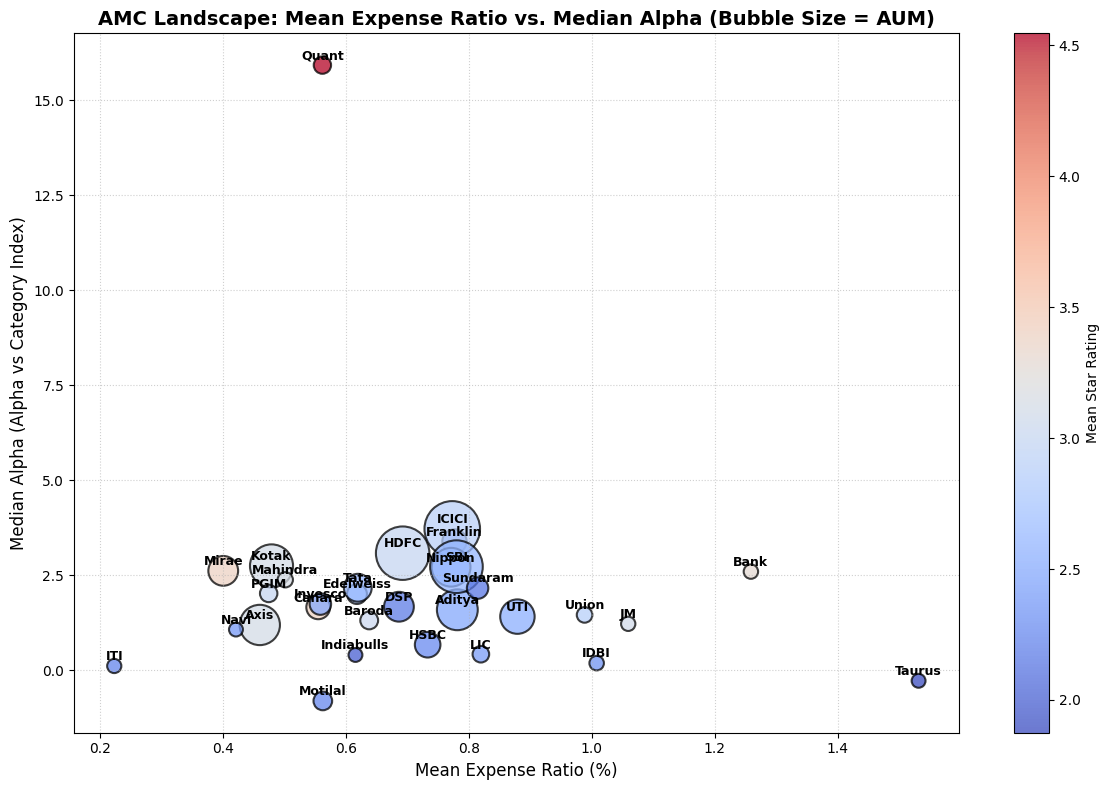

In [88]:
# 3. Bubble Chart: Expense Ratio vs Median Alpha (size scaled by Total AUM)
plt.figure(figsize=(12, 8))

x_val = amc_scorecard['mean_expense_ratio'].values
y_val = amc_scorecard['median_alpha'].values
# Scale bubble sizes for visual clarity (min size 100, max size 2000)
aum_val = amc_scorecard['total_aum_cr'].values
sizes = 100 + (aum_val - aum_val.min()) / (aum_val.max() - aum_val.min() + 1e-9) * 1500

scatter = plt.scatter(x_val, y_val, s=sizes, c=amc_scorecard['mean_rating'], cmap='coolwarm',
            alpha=0.75, edgecolors='black', linewidths=1.5)

# Annotate the names on each bubble
for i, amc_name in enumerate(amc_scorecard.index):
    plt.text(x_val[i], y_val[i] + 0.15, amc_name.split(' ')[0], ha='center', fontsize=9, fontweight='bold')

plt.title('AMC Landscape: Mean Expense Ratio vs. Median Alpha (Bubble Size = AUM)', fontsize=14, fontweight='bold')
plt.xlabel('Mean Expense Ratio (%)', fontsize=12)
plt.ylabel('Median Alpha (Alpha vs Category Index)', fontsize=12)
plt.colorbar(scatter, label='Mean Star Rating')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [89]:
# 4. Formulate overall Rank by assigning equal weights to normalized columns:
# Score = (Mean Rating + Median Alpha + Median Sharpe + Cheapness (Inv Exp) + Peer Beat %) / 5

amc_scaled['overall_score'] = amc_scaled.mean(axis=1)
ranked_amcs = amc_scaled.sort_values(by='overall_score', ascending=False)
print("=== Overall Ranked AMCs ===")
display(ranked_amcs[['overall_score']])

=== Overall Ranked AMCs ===


,overall_score
amc_name,
Quant Mutual Fund,0.796434
HDFC Mutual Fund,0.606203
ICICI Prudential Mutual Fund,0.600335
Kotak Mahindra Mutual Fund,0.572915
SBI Mutual Fund,0.501545
Mirae Asset Mutual Fund,0.497640
Nippon India Mutual Fund,0.474142
Mahindra Manulife Mutual Fund,0.451511
Axis Mutual Fund,0.446218


### Strategic Analysis: Top 5 vs. Bottom 5 Asset Management Companies (AMCs)

#### What Separates the Top 5 from the Bottom 5 AMCs?

1. **Alpha Generation and Risk-Efficiency:**
   * **Top 5 AMCs:** Consistently register high positive median **Alpha** and strong **Sharpe ratios**. They show superior security selection and asset allocation, resulting in a high percentage of their individual funds outperforming their specific sub-category medians (frequently $> 60\%$).
   * **Bottom 5 AMCs:** Show flat or negative median Alphas, and substantially lower Sharpe ratios. Their active bets do not yield index-beating returns relative to the risks taken.

2. **Pricing and Expense Ratio Structure (Cost Penalty):**
   * **Top 5 AMCs:** Often leverage scale to lower average expense ratios, or deliver high-performance gains that more than justify active fees.
   * **Bottom 5 AMCs:** Tend to carry high expense ratios on average, which acts as a major drag on active performance, especially in passive-heavy market environments.

3. **Consistency and Size Adaptability:**
   * **Top 5 AMCs:** Maintain structural superiority across multiple fund categories (Equity, Debt, and Hybrid), whereas **Bottom 5 AMCs** might have a single high-performing fund but struggle with overall underperformance across the rest of their portfolio offerings.

### Findings on the Fund Size "Sweet Spot"

Based on the generated plots:

1. **Equity Funds:**
   * **Sweet Spot:** Medium to Large funds (buckets **S3 (M)** to **S4 (L)**) tend to maintain healthy Alphas and robust 3-year returns.
   * **Alpha Drop-off:** There is often a noticeable reduction or flattening out of median Alpha when transitioning to the largest size bracket, **S5 (XL)**. This is a classic indication of "size drag," where extremely large funds struggle to deploy capital in high-conviction, high-growth mid/small-caps without moving market prices.

2. **Debt Funds:**
   * **Sweet Spot:** Scaled Debt funds (brackets **S4 (L)** and **S5 (XL)**) often perform better. Larger debt funds generally benefit from superior institutional pricing, lower transaction costs, and more diversified debt instruments.

3. **Hybrid Funds:**
   * **Sweet Spot:** Typically, intermediate buckets offer the most balanced performance before narrowing out or facing minor drops as asset size gets excessively large.

In [90]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Clean and prepare dataset for fund manager level analysis
df_mgr = df_clean.copy()
df_mgr['returns_3yr'] = pd.to_numeric(df_mgr['returns_3yr'], errors='coerce')

# Drop records without valid 3-year returns or sub-category / manager mappings
df_mgr = df_mgr.dropna(subset=['returns_3yr', 'sub_category', 'fund_manager']).copy()

# 2. Compute Relative Performance (returns_3yr minus sub_category median)
sub_medians = df_mgr.groupby('sub_category')['returns_3yr'].transform('median')
df_mgr['relative_performance'] = df_mgr['returns_3yr'] - sub_medians
df_mgr['beats_median'] = df_mgr['relative_performance'] > 0

# 3. Filter for managers running at least 3 funds
mgr_counts = df_mgr['fund_manager'].value_counts()
eligible_mgrs = mgr_counts[mgr_counts >= 3].index
df_eligible_mgr = df_mgr[df_mgr['fund_manager'].isin(eligible_mgrs)].copy()

# 4. Aggregate metrics per fund manager
mgr_scorecard = df_eligible_mgr.groupby('fund_manager').agg(
    mean_relative_return=('relative_performance', 'mean'),
    std_relative_return=('relative_performance', 'std'),
    fund_count=('relative_performance', 'count'),
    win_rate=('beats_median', lambda x: x.mean() * 100)
).reset_index()

# Display the top 5 and bottom 5 managers to verify calculations
print("=== Top 5 Managers (Relative Performance) ===")
display(mgr_scorecard.sort_values(by='mean_relative_return', ascending=False).head(5))

print("\n=== Bottom 5 Managers (Relative Performance) ===")
display(mgr_scorecard.sort_values(by='mean_relative_return', ascending=True).head(5))

=== Top 5 Managers (Relative Performance) ===


,fund_manager,mean_relative_return,std_relative_return,fund_count,win_rate
113,Vasav Sahgal,26.112500,6.543747,4,100.000000
94,Sanjeev Sharma,12.457143,9.484919,7,100.000000
31,Dharmesh Kakkad,10.308333,9.874939,6,83.333333
104,Srinivasan Ramamurthy,9.233333,9.404432,3,66.666667
70,Piyush Baranwal,9.133333,16.772100,3,33.333333



=== Bottom 5 Managers (Relative Performance) ===


,fund_manager,mean_relative_return,std_relative_return,fund_count,win_rate
99,Shreyash Devalkar,-6.966667,0.971253,3,0.0
49,Jinesh Gopani,-6.837500,5.450287,4,0.0
35,Dhimant Shah,-6.366667,5.315386,3,0.0
20,Atul Penkar,-6.250000,4.707175,3,0.0
120,Vinit Sambre,-4.762500,4.253503,4,0.0


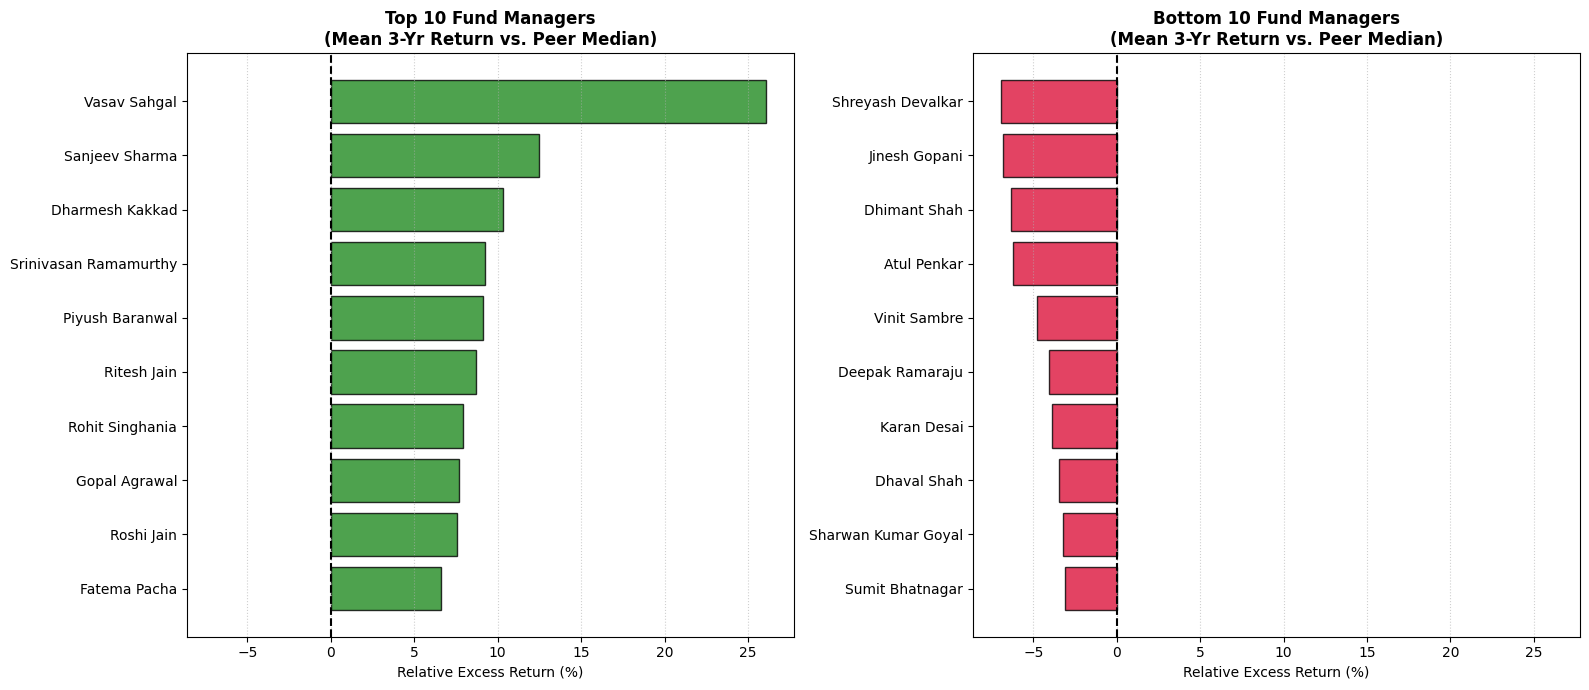

In [91]:
# 5. Plot the Top and Bottom 10 Managers as a horizontal bar chart
top_10 = mgr_scorecard.nlargest(10, 'mean_relative_return').sort_values(by='mean_relative_return', ascending=True)
bot_10 = mgr_scorecard.nsmallest(10, 'mean_relative_return').sort_values(by='mean_relative_return', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True)

# Plot Top 10
axes[0].barh(top_10['fund_manager'], top_10['mean_relative_return'], color='forestgreen', edgecolor='black', alpha=0.8)
axes[0].axvline(0, color='black', linestyle='--')
axes[0].set_title('Top 10 Fund Managers\n(Mean 3-Yr Return vs. Peer Median)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Relative Excess Return (%)')
axes[0].grid(True, axis='x', linestyle=':', alpha=0.6)

# Plot Bottom 10
axes[1].barh(bot_10['fund_manager'], bot_10['mean_relative_return'], color='crimson', edgecolor='black', alpha=0.8)
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title('Bottom 10 Fund Managers\n(Mean 3-Yr Return vs. Peer Median)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Relative Excess Return (%)')
axes[1].grid(True, axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

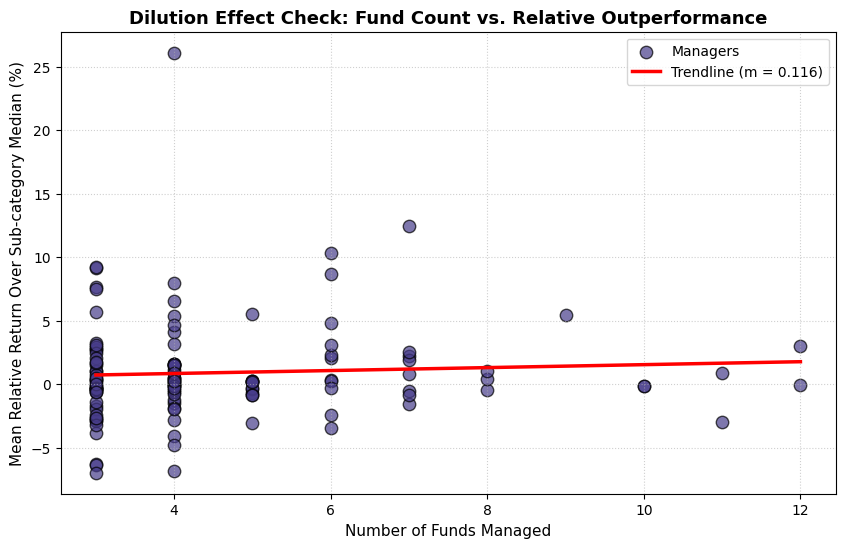

In [92]:
# 6. Test Dilution Effect: Scatter of Fund Count vs. Mean Relative Return
plt.figure(figsize=(10, 6))
x_funds = mgr_scorecard['fund_count'].values
y_rel = mgr_scorecard['mean_relative_return'].values

plt.scatter(x_funds, y_rel, s=80, color='darkslateblue', alpha=0.7, edgecolor='k', label='Managers')

# Fit a trendline using np.polyfit
slope, intercept = np.polyfit(x_funds, y_rel, 1)
x_line = np.linspace(x_funds.min(), x_funds.max(), 100)
plt.plot(x_line, slope * x_line + intercept, color='red', linestyle='-', linewidth=2.5,
         label=f'Trendline (m = {slope:.3f})')

plt.title('Dilution Effect Check: Fund Count vs. Relative Outperformance', fontsize=13, fontweight='bold')
plt.xlabel('Number of Funds Managed', fontsize=11)
plt.ylabel('Mean Relative Return Over Sub-category Median (%)', fontsize=11)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Clean and prepare data
df_audit = df_clean.copy()
df_audit['risk_level'] = pd.to_numeric(df_audit['risk_level'], errors='coerce')
df_audit['sd'] = pd.to_numeric(df_audit['sd'], errors='coerce')
df_audit['beta'] = pd.to_numeric(df_audit['beta'], errors='coerce')
df_audit['returns_3yr'] = pd.to_numeric(df_audit['returns_3yr'], errors='coerce')

# Drop records missing crucial volatility metrics
df_audit = df_audit.dropna(subset=['risk_level', 'sd', 'beta', 'category', 'sub_category']).copy()
df_audit['risk_level'] = df_audit['risk_level'].astype(int)

print(f"Total funds analyzed for risk label audit: {len(df_audit)}")

Total funds analyzed for risk label audit: 746


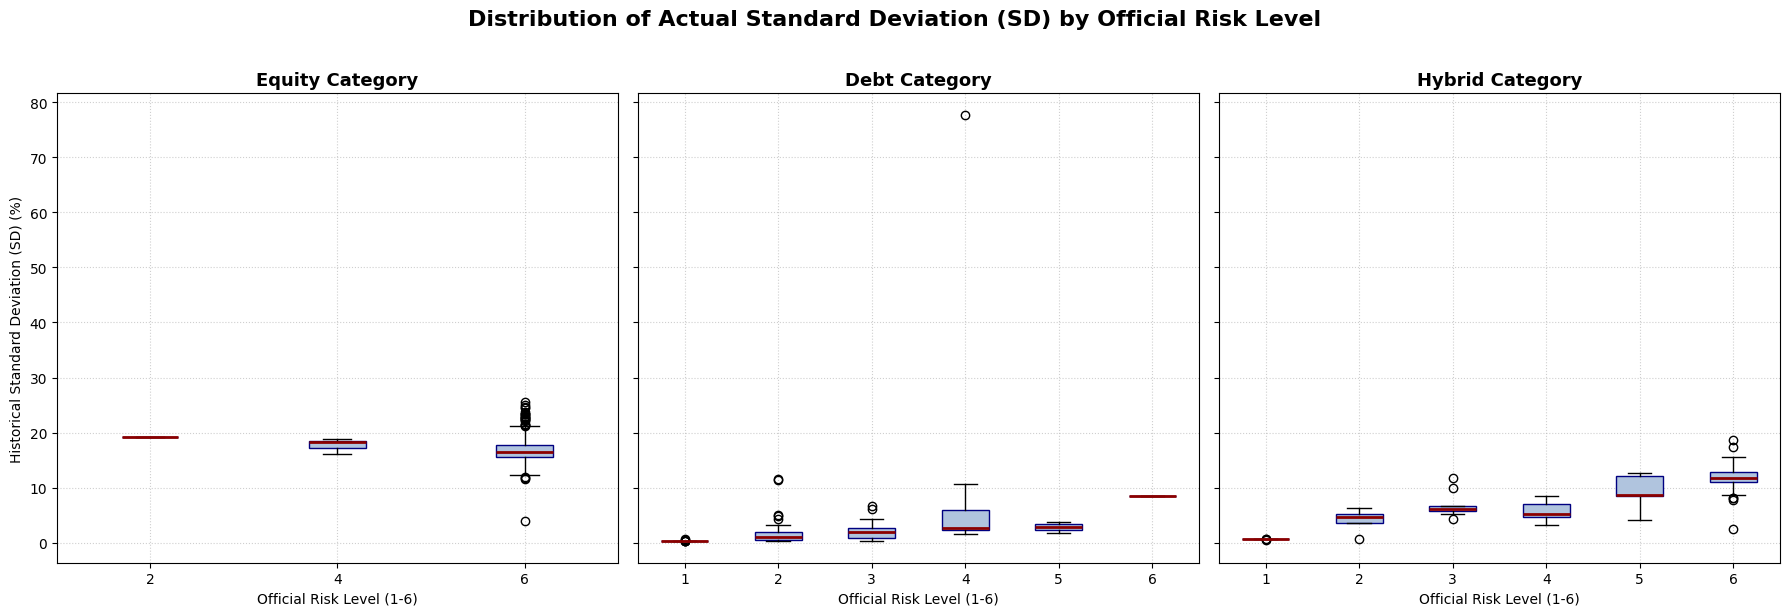

In [94]:
# 2. Draw boxplots of SD by risk_level for each Category using subplots
categories = ['Equity', 'Debt', 'Hybrid']
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
fig.suptitle('Distribution of Actual Standard Deviation (SD) by Official Risk Level', fontsize=16, fontweight='bold', y=1.02)

for idx, cat in enumerate(categories):
    cat_data = df_audit[df_audit['category'] == cat]
    unique_risks = sorted(cat_data['risk_level'].unique())

    groups = [cat_data[cat_data['risk_level'] == r]['sd'].values for r in unique_risks]

    ax = axes[idx]
    ax.boxplot(groups, tick_labels=unique_risks, patch_artist=True,
               boxprops=dict(facecolor='lightsteelblue', color='navy'),
               medianprops=dict(color='darkred', linewidth=2))
    ax.set_title(f'{cat} Category', fontsize=13, fontweight='bold')
    ax.set_xlabel('Official Risk Level (1-6)')
    if idx == 0:
        ax.set_ylabel('Historical Standard Deviation (SD) (%)')
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [95]:
# 3. Flag "Understated Risk" funds: risk_level <= 3 whose SD exceeds their category's 75th percentile
understated_funds_list = []

for cat in categories:
    cat_df = df_audit[df_audit['category'] == cat].copy()
    q75_sd = cat_df['sd'].quantile(0.75)

    # Identify funds with low declared risk but high actual volatility
    flagged = cat_df[(cat_df['risk_level'] <= 3) & (cat_df['sd'] > q75_sd)].copy()
    flagged['category_q75_sd'] = q75_sd
    understated_funds_list.append(flagged)

df_understated = pd.concat(understated_funds_list, ignore_index=True)

print(f"=== Understated Risk Summary ===")
print(f"Total funds classified as Understated Risk: {len(df_understated)}\n")

# Group by sub-category to see where understated risk labels are most prevalent
understated_by_sub = df_understated['sub_category'].value_counts().reset_index()
understated_by_sub.columns = ['sub_category', 'understated_count']

# Get total count of funds in those sub-categories to find prevalence proportion
total_by_sub = df_audit['sub_category'].value_counts().reset_index()
total_by_sub.columns = ['sub_category', 'total_count']

understated_stats = pd.merge(understated_by_sub, total_by_sub, on='sub_category')
understated_stats['prevalence_share_%'] = (understated_stats['understated_count'] / understated_stats['total_count']) * 100

print("=== Top Sub-Categories with Consistently Understated Risk ===")
display(understated_stats.sort_values(by='prevalence_share_%', ascending=False).head(10))

=== Understated Risk Summary ===
Total funds classified as Understated Risk: 55

=== Top Sub-Categories with Consistently Understated Risk ===


,sub_category,understated_count,total_count,prevalence_share_%
7,Fixed Maturity Plans,2,2,100.000000
2,Medium to Long Duration Funds,10,11,90.909091
0,Gilt Mutual Funds,16,19,84.210526
1,Dynamic Bond,11,21,52.380952
6,Medium Duration Funds,3,12,25.000000
3,Short Duration Funds,4,21,19.047619
5,Banking and PSU Mutual Funds,3,17,17.647059
4,Low Duration Funds,3,20,15.000000
9,Credit Risk Funds,1,14,7.142857
10,Conservative Hybrid Mutual Funds,1,17,5.882353


In [96]:
# 4. Compute Efficiency = returns_3yr / SD and show top/bottom 10
df_audit['efficiency'] = df_audit['returns_3yr'] / df_audit['sd']

# Drop any records where efficiency is infinite or null
df_eff = df_audit[np.isfinite(df_audit['efficiency'])].copy()

top_10_eff = df_eff.nlargest(10, 'efficiency')
bot_10_eff = df_eff.nsmallest(10, 'efficiency')

print("=== Top 10 Most Efficient Funds (3-Yr Return / SD) ===")
display(top_10_eff[['scheme_name', 'category', 'sub_category', 'returns_3yr', 'sd', 'efficiency']])

print("\n=== Top 10 Least Efficient Funds (3-Yr Return / SD) ===")
display(bot_10_eff[['scheme_name', 'category', 'sub_category', 'returns_3yr', 'sd', 'efficiency']])

=== Top 10 Most Efficient Funds (3-Yr Return / SD) ===


,scheme_name,category,sub_category,returns_3yr,sd,efficiency
538,Navi Ultra Short Term Fund,Debt,Ultra Short Duration Funds,32.4,0.36,90.000000
812,WhiteOak Capital Overnight Fund,Debt,Overnight Mutual Funds,32.4,0.39,83.076923
605,Quant Liquid Plan – Direct Growth,Debt,Liquid Mutual Funds,4.9,0.27,18.148148
267,HSBC Corporate Bond Fund,Debt,Corporate Bond Mutual Funds,32.4,2.47,13.117409
275,HSBC Flexi Debt Fund,Debt,Dynamic Bond,32.4,2.47,13.117409
362,IDBI Liquid Fund,Debt,Liquid Mutual Funds,4.4,0.36,12.222222
490,Mahindra Manulife Liquid Fund,Debt,Liquid Mutual Funds,4.5,0.37,12.162162
475,LIC MF Liquid Fund,Debt,Liquid Mutual Funds,4.4,0.37,11.891892
194,Edelweiss Overnight Fund,Debt,Overnight Mutual Funds,3.9,0.33,11.818182
596,PGIM India Overnight Fund,Debt,Overnight Mutual Funds,3.9,0.33,11.818182



=== Top 10 Least Efficient Funds (3-Yr Return / SD) ===


,scheme_name,category,sub_category,returns_3yr,sd,efficiency
89,Bank of India Credit Risk Fund,Debt,Credit Risk Funds,12.8,77.72,0.164694
213,Franklin India Multi-Asset Solution Fund,Other,FoFs Domestic,8.7,12.82,0.678627
0,Aditya Birla SL Active Debt Multi-Mgr FoF-Dir ...,Other,FoFs Domestic,6.5,9.39,0.692226
358,IDBI Gold Fund,Other,FoFs Domestic,12.1,16.54,0.731560
97,Bank of India Short Term Income – Direct Growth,Debt,Short Duration Funds,8.8,11.44,0.769231
393,Invesco India Gold Fund,Other,FoFs Domestic,11.5,14.79,0.777552
62,AXIS Focused 25 Fund,Equity,Focused Funds,14.8,18.84,0.785563
551,Nippon India Gold Savings Fund,Other,FoFs Domestic,11.7,14.76,0.792683
781,UTI-Credit Risk Fund,Debt,Credit Risk Funds,8.3,10.47,0.792741
359,IDBI Healthcare Fund,Equity,Sectoral / Thematic Mutual Funds,17.1,20.52,0.833333


In [97]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Clean the min_sip and other required evaluation columns
df_sip = df_clean.copy()
df_sip['min_sip'] = pd.to_numeric(df_sip['min_sip'], errors='coerce')
df_sip['expense_ratio'] = pd.to_numeric(df_sip['expense_ratio'], errors='coerce')
df_sip['rating'] = pd.to_numeric(df_sip['rating'], errors='coerce')
df_sip['returns_3yr'] = pd.to_numeric(df_sip['returns_3yr'], errors='coerce')
df_sip['risk_level'] = pd.to_numeric(df_sip['risk_level'], errors='coerce')
df_sip['alpha'] = pd.to_numeric(df_sip['alpha'], errors='coerce')
df_sip['sharpe'] = pd.to_numeric(df_sip['sharpe'], errors='coerce')

# Drop records with missing values in min_sip or category
df_sip = df_sip.dropna(subset=['min_sip', 'category']).copy()

# Define the bins and labels for min_sip
# Buckets: Under 100, 100-500, 500-1000, 1000-2000, 2000+
bins = [-1, 100, 500, 1000, 2000, np.inf]
labels = ['<= 100', '101 - 500', '501 - 1000', '1001 - 2000', '2000+']
df_sip['sip_bucket'] = pd.cut(df_sip['min_sip'], bins=bins, labels=labels)

# Verify counts in each bucket
print("=== Fund Counts by Minimum SIP Bucket ===")
print(df_sip['sip_bucket'].value_counts().sort_index())

=== Fund Counts by Minimum SIP Bucket ===
sip_bucket
<= 100         172
101 - 500      400
501 - 1000     208
1001 - 2000      9
2000+            0
Name: count, dtype: int64


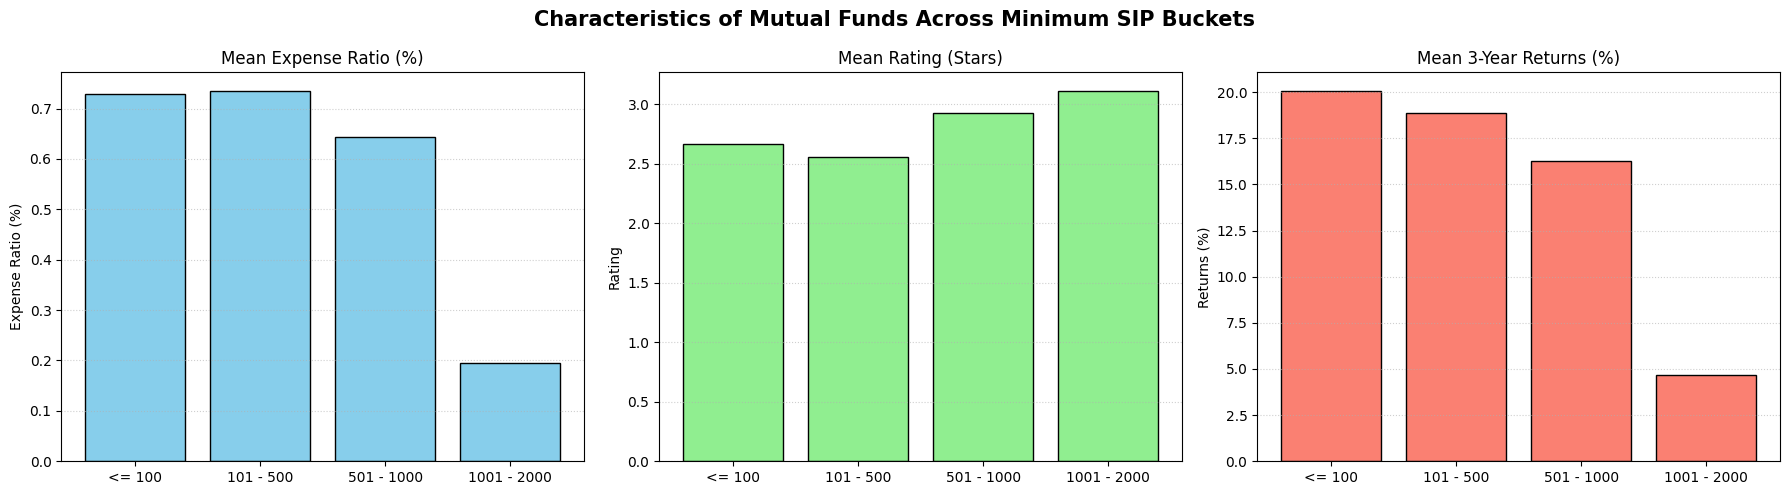

In [98]:
# 2. Compare performance, fees, and ratings across the SIP buckets
sip_comparison = df_sip.groupby('sip_bucket', observed=False).agg(
    mean_expense_ratio=('expense_ratio', 'mean'),
    mean_rating=('rating', 'mean'),
    mean_returns_3yr=('returns_3yr', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Characteristics of Mutual Funds Across Minimum SIP Buckets', fontsize=15, fontweight='bold')

# Bar Chart 1: Expense Ratio
axes[0].bar(sip_comparison['sip_bucket'], sip_comparison['mean_expense_ratio'], color='skyblue', edgecolor='black')
axes[0].set_title('Mean Expense Ratio (%)')
axes[0].set_ylabel('Expense Ratio (%)')
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

# Bar Chart 2: Rating
axes[1].bar(sip_comparison['sip_bucket'], sip_comparison['mean_rating'], color='lightgreen', edgecolor='black')
axes[1].set_title('Mean Rating (Stars)')
axes[1].set_ylabel('Rating')
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

# Bar Chart 3: 3-Year Returns
axes[2].bar(sip_comparison['sip_bucket'], sip_comparison['mean_returns_3yr'], color='salmon', edgecolor='black')
axes[2].set_title('Mean 3-Year Returns (%)')
axes[2].set_ylabel('Returns (%)')
axes[2].grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [99]:
# 3. Build a beginner shortlist
# First find category-wise median expense ratios
cat_medians = df_sip.groupby('category')['expense_ratio'].transform('median')
df_sip['cat_median_expense'] = cat_medians

# Filter funds matching the user's constraints:
# - min_sip <= 500
# - expense_ratio < category's median expense ratio
# - rating >= 4
# - risk_level <= 4
# - alpha > 0
shortlist = df_sip[
    (df_sip['min_sip'] <= 500) &
    (df_sip['expense_ratio'] < df_sip['cat_median_expense']) &
    (df_sip['rating'] >= 4) &
    (df_sip['risk_level'] <= 4) &
    (df_sip['alpha'] > 0)
].copy()

print(f"Total funds meeting beginner criteria: {len(shortlist)}")

# Select top 5 per category based on 3-year returns
top_shortlist = shortlist.groupby('category').apply(
    lambda x: x.sort_values(by='returns_3yr', ascending=False).head(5),
    include_groups=False
).reset_index()

print("=== Top 5 Beginner-Friendly Funds per Category ===")
display(top_shortlist[['category', 'scheme_name', 'min_sip', 'expense_ratio', 'rating', 'risk_level', 'alpha', 'returns_3yr', 'sharpe']])

Total funds meeting beginner criteria: 32
=== Top 5 Beginner-Friendly Funds per Category ===


,category,scheme_name,min_sip,expense_ratio,rating,risk_level,alpha,returns_3yr,sharpe
0,Debt,IDBI Short Term Bond Fund,500,0.28,4,2,3.82,9.4,0.92
1,Debt,Sundaram Corporate Bond Fund,250,0.28,4,2,1.84,6.8,1.15
2,Debt,HDFC Floating Rate Debt Fund,100,0.26,4,3,3.39,6.5,1.76
3,Debt,Franklin India Floating Rate Fund,500,0.21,4,2,2.33,5.6,1.58
4,Debt,Tata Money Market Fund,150,0.17,5,3,2.92,5.6,2.05
5,Hybrid,Tata Balanced Advantage Fund,150,0.28,4,4,3.80,18.7,1.69
6,Hybrid,Sundaram Equity Savings Fund,500,0.54,4,3,2.50,16.8,1.50
7,Hybrid,UTI-Equity Savings Fund,0,0.68,4,3,3.98,14.7,1.75
8,Hybrid,Sundaram Balanced Advantage Fund,500,0.62,5,4,2.13,11.9,1.51
9,Hybrid,Edelweiss Arbitrage Fund,500,0.37,5,1,1.78,5.0,1.31


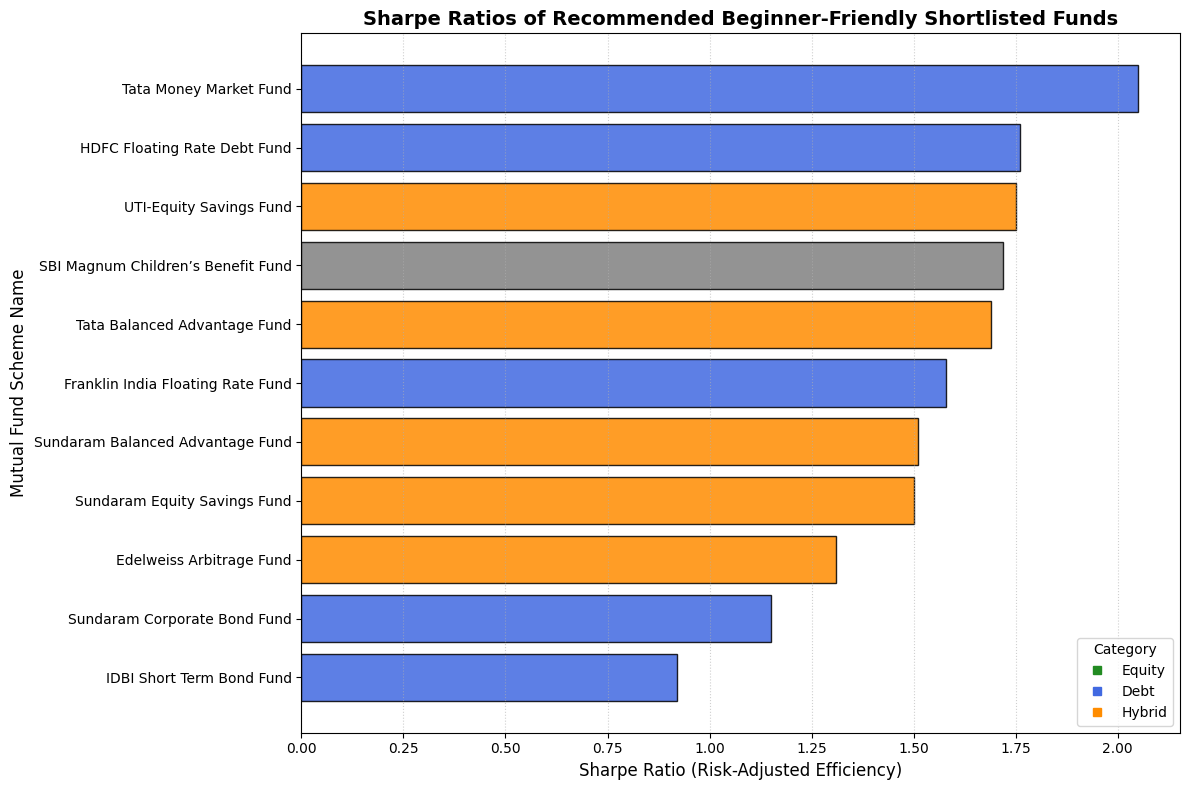

In [100]:
# 4. Visualize the Sharpe ratios of the shortlisted top funds
plt.figure(figsize=(12, 8))

# Sort for visual presentation in the horizontal bar chart
top_shortlist_sorted = top_shortlist.sort_values(by='sharpe', ascending=True)

# Generate unique colors per category
category_colors = {'Equity': 'forestgreen', 'Debt': 'royalblue', 'Hybrid': 'darkorange'}
colors = [category_colors.get(cat, 'gray') for cat in top_shortlist_sorted['category']]

bars = plt.barh(top_shortlist_sorted['scheme_name'].apply(lambda x: x[:40]),
                 top_shortlist_sorted['sharpe'],
                 color=colors, edgecolor='black', alpha=0.85)

# Add legend labels by manual proxy plotting
for cat, col in category_colors.items():
    plt.plot([], [], color=col, label=cat, marker='s', linestyle='')
plt.legend(title='Category', loc='lower right')

plt.title('Sharpe Ratios of Recommended Beginner-Friendly Shortlisted Funds', fontsize=14, fontweight='bold')
plt.xlabel('Sharpe Ratio (Risk-Adjusted Efficiency)', fontsize=12)
plt.ylabel('Mutual Fund Scheme Name', fontsize=12)
plt.grid(True, axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

In [101]:
# 1. Trajectory Labeling: Short-term vs. Long-term Returns Analysis
df_traj = df_clean.copy()
df_traj['returns_1yr'] = pd.to_numeric(df_traj['returns_1yr'], errors='coerce')
df_traj['returns_3yr'] = pd.to_numeric(df_traj['returns_3yr'], errors='coerce')
df_traj['returns_5yr'] = pd.to_numeric(df_traj['returns_5yr'], errors='coerce')

# Filter for funds that have all three return horizons available
df_traj = df_traj.dropna(subset=['returns_1yr', 'returns_3yr', 'returns_5yr', 'sub_category']).copy()

# Define trajectories:
# - accelerating: returns_1yr > returns_5yr + threshold
# - fading: returns_1yr < returns_5yr - threshold
# - steady: everything in between (within threshold band)
threshold = 2.0  # 2% return difference threshold

def classify_trajectory(row, t=threshold):
    ret_1y = row['returns_1yr']
    ret_5y = row['returns_5yr']
    if ret_1y > ret_5y + t:
        return 'accelerating'
    elif ret_1y < ret_5y - t:
        return 'fading'
    else:
        return 'steady'

df_traj['trajectory'] = df_traj.apply(classify_trajectory, axis=1)

print(f"Total labeled funds: {len(df_traj)}")
print(df_traj['trajectory'].value_counts(normalize=True).round(3) * 100)

Total labeled funds: 631
trajectory
fading          67.8
steady          27.1
accelerating     5.1
Name: proportion, dtype: float64


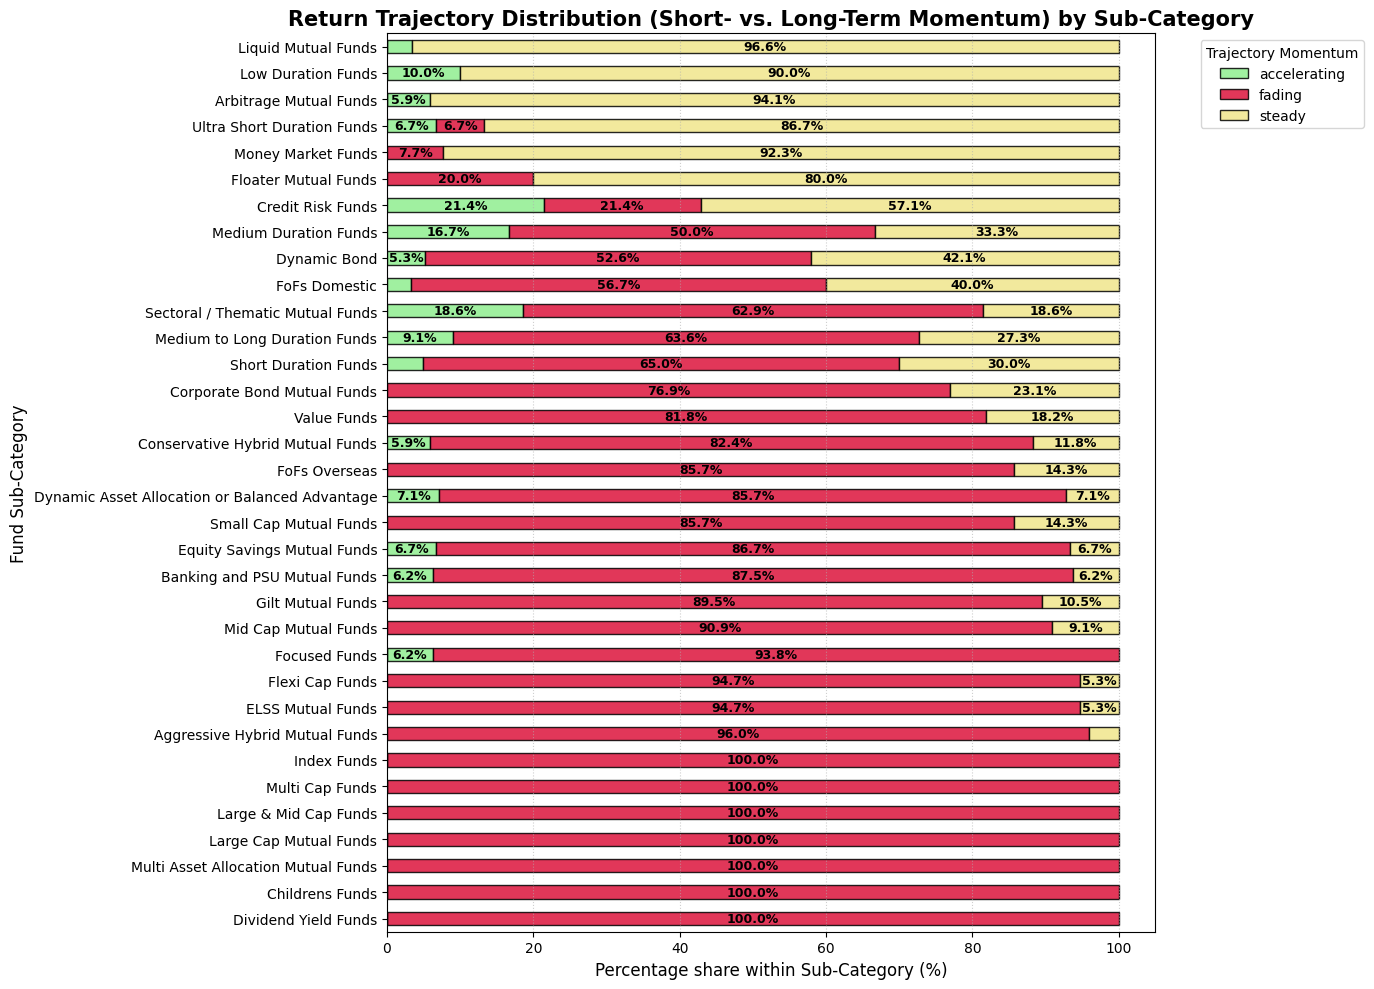

In [102]:
# 2. Calculate the proportion of each label by sub-category
# Filter for sub-categories with at least 5 funds for statistical consistency
eligible_subs = df_traj['sub_category'].value_counts()[df_traj['sub_category'].value_counts() >= 5].index
df_traj_filtered = df_traj[df_traj['sub_category'].isin(eligible_subs)]

traj_matrix = pd.crosstab(
    df_traj_filtered['sub_category'],
    df_traj_filtered['trajectory'],
    normalize='index'
) * 100

# Order by percentage of fading funds to highlight the most vulnerable sub-categories
traj_matrix_sorted = traj_matrix.sort_values(by='fading', ascending=False)

# Plot the stacked bar chart
fig, ax = plt.subplots(figsize=(14, 10))
traj_matrix_sorted.plot(kind='barh', stacked=True, color=['lightgreen', 'crimson', 'khaki'], ax=ax, edgecolor='black', alpha=0.85)

plt.title('Return Trajectory Distribution (Short- vs. Long-Term Momentum) by Sub-Category', fontsize=15, fontweight='bold')
plt.xlabel('Percentage share within Sub-Category (%)', fontsize=12)
plt.ylabel('Fund Sub-Category', fontsize=12)
plt.legend(title='Trajectory Momentum', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='x', linestyle=':', alpha=0.6)

# Annotate percentages inside bars
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    if width > 5:
        x, y = p.get_xy()
        ax.text(x + width/2, y + height/2, f'{width:.1f}%',
                va='center', ha='center', fontsize=9, fontweight='semibold', color='black')

plt.tight_layout()
plt.show()

In [103]:
# 1. Prepare and filter the recommendation dataset
df_rec = df_clean.copy()

rec_features = ['sharpe', 'alpha', 'returns_3yr', 'expense_ratio', 'sd']
for col in rec_features + ['risk_level', 'min_sip']:
    df_rec[col] = pd.to_numeric(df_rec[col], errors='coerce')

# Drop rows with nulls in target features
df_rec = df_rec.dropna(subset=rec_features + ['category', 'sub_category', 'risk_level', 'min_sip']).copy()

# 2. Min-Max Normalization
# Create normalized columns where 1 is the best possible and 0 is the worst
for col in ['sharpe', 'alpha', 'returns_3yr']:
    col_min = df_rec[col].min()
    col_max = df_rec[col].max()
    df_rec[f'norm_{col}'] = (df_rec[col] - col_min) / (col_max - col_min + 1e-9)

# Inverted metrics (lower is better)
for col in ['expense_ratio', 'sd']:
    col_min = df_rec[col].min()
    col_max = df_rec[col].max()
    df_rec[f'norm_{col}'] = 1.0 - ((df_rec[col] - col_min) / (col_max - col_min + 1e-9))

# 3. Adjustable Recommendation Engine Function
def recommend(risk_level_max=4, min_sip_max=500, category=None, weights=None, top_n=10):
    """
    Returns top ranked mutual funds based on custom weight factor score allocations.
    Default weights are equal (0.2 each).
    """
    if weights is None:
        weights = {
            'sharpe': 0.2,
            'alpha': 0.2,
            'returns_3yr': 0.2,
            'expense_ratio': 0.2,
            'sd': 0.2
        }

    # Normalize weights to sum to 1.0
    total_w = sum(weights.values())
    norm_w = {k: v / total_w for k, v in weights.items()}

    # Filter by user constraints
    filtered_df = df_rec[
        (df_rec['risk_level'] <= risk_level_max) &
        (df_rec['min_sip'] <= min_sip_max)
    ].copy()

    if category:
        filtered_df = filtered_df[filtered_df['category'] == category].copy()

    if len(filtered_df) == 0:
        print("No funds found matching the specified criteria.")
        return pd.DataFrame()

    # Calculate overall weighted score
    filtered_df['overall_score'] = (
        filtered_df['norm_sharpe'] * norm_w['sharpe'] +
        filtered_df['norm_alpha'] * norm_w['alpha'] +
        filtered_df['norm_returns_3yr'] * norm_w['returns_3yr'] +
        filtered_df['norm_expense_ratio'] * norm_w['expense_ratio'] +
        filtered_df['norm_sd'] * norm_w['sd']
    )

    # Store absolute contributions for visualization
    filtered_df['contrib_sharpe'] = filtered_df['norm_sharpe'] * norm_w['sharpe']
    filtered_df['contrib_alpha'] = filtered_df['norm_alpha'] * norm_w['alpha']
    filtered_df['contrib_returns_3yr'] = filtered_df['norm_returns_3yr'] * norm_w['returns_3yr']
    filtered_df['contrib_expense_ratio'] = filtered_df['norm_expense_ratio'] * norm_w['expense_ratio']
    filtered_df['contrib_sd'] = filtered_df['norm_sd'] * norm_w['sd']

    return filtered_df.sort_values(by='overall_score', ascending=False).head(top_n)

# Test Engine: Request top 10 Moderate-Risk & Budget-Friendly Equity Funds
custom_weights = {
    'sharpe': 0.3,
    'alpha': 0.2,
    'returns_3yr': 0.2,
    'expense_ratio': 0.15,
    'sd': 0.15
}

recommendations = recommend(
    risk_level_max=4,
    min_sip_max=500,
    category='Equity',
    weights=custom_weights,
    top_n=10
)

display(recommendations[['scheme_name', 'sub_category', 'risk_level', 'min_sip', 'overall_score']])

,scheme_name,sub_category,risk_level,min_sip,overall_score
678,Sundaram Emerging Small Cap Series III – Dir G...,Small Cap Mutual Funds,2,0,0.640903
679,Sundaram Emerging Small Cap Series IV – Dir Gr...,Small Cap Mutual Funds,4,0,0.623389
639,SBI Long Term Advantage Fund,ELSS Mutual Funds,4,0,0.587588
663,SBI Tax Advantage Fund,ELSS Mutual Funds,4,0,0.577921


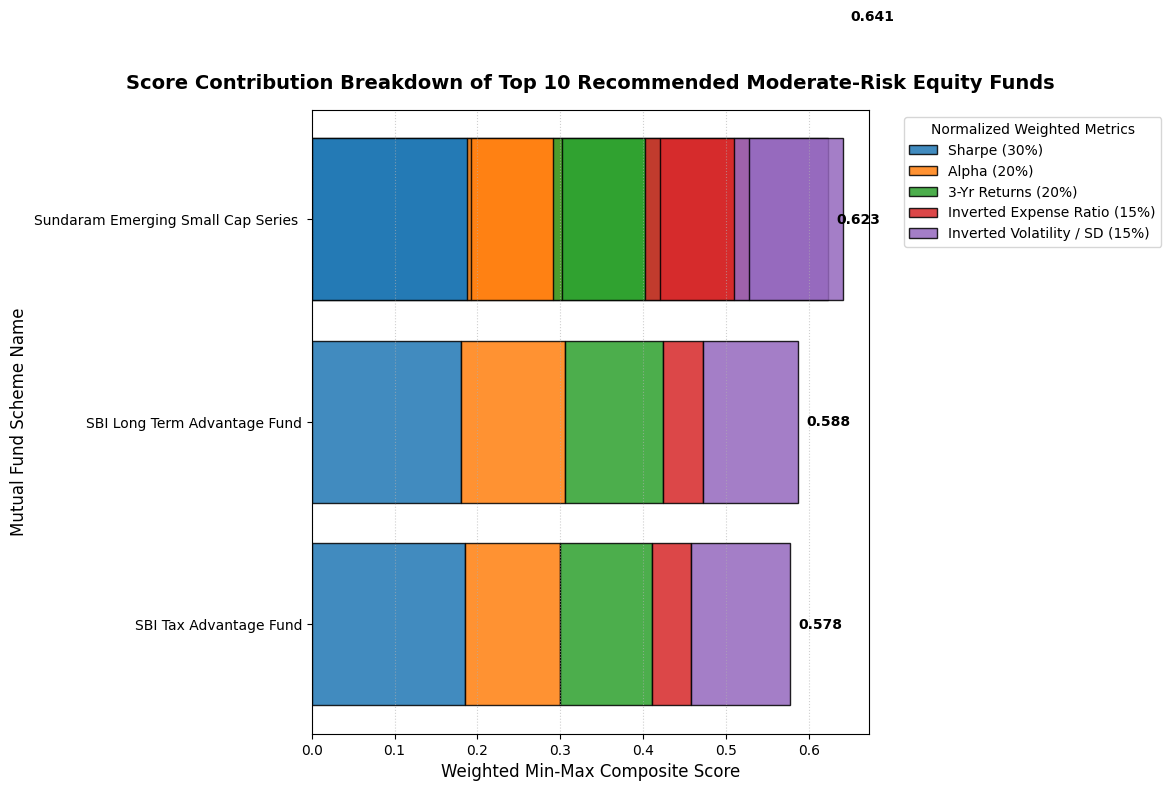

In [104]:
# 4. Plot Score Contributions of Top 10 Recommended Funds
if not recommendations.empty:
    plt.figure(figsize=(12, 8))

    # Sort ascending for horizontal bar stack visual
    plot_df = recommendations.sort_values(by='overall_score', ascending=True)

    schemes = plot_df['scheme_name'].apply(lambda x: x[:35]).values

    # Stack base arrays
    c_sharpe = plot_df['contrib_sharpe'].values
    c_alpha = plot_df['contrib_alpha'].values
    c_ret = plot_df['contrib_returns_3yr'].values
    c_exp = plot_df['contrib_expense_ratio'].values
    c_sd = plot_df['contrib_sd'].values

    # Generate horizontal stacked bars
    b1 = plt.barh(schemes, c_sharpe, color='#1f77b4', label='Sharpe (30%)', edgecolor='black', alpha=0.85)
    b2 = plt.barh(schemes, c_alpha, left=c_sharpe, color='#ff7f0e', label='Alpha (20%)', edgecolor='black', alpha=0.85)
    b3 = plt.barh(schemes, c_ret, left=c_sharpe + c_alpha, color='#2ca02c', label='3-Yr Returns (20%)', edgecolor='black', alpha=0.85)
    b4 = plt.barh(schemes, c_exp, left=c_sharpe + c_alpha + c_ret, color='#d62728', label='Inverted Expense Ratio (15%)', edgecolor='black', alpha=0.85)
    b5 = plt.barh(schemes, c_sd, left=c_sharpe + c_alpha + c_ret + c_exp, color='#9467bd', label='Inverted Volatility / SD (15%)', edgecolor='black', alpha=0.85)

    plt.title('Score Contribution Breakdown of Top 10 Recommended Moderate-Risk Equity Funds', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Weighted Min-Max Composite Score', fontsize=12)
    plt.ylabel('Mutual Fund Scheme Name', fontsize=12)
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Normalized Weighted Metrics')
    plt.grid(axis='x', linestyle=':', alpha=0.6)

    # Print scores beside bars
    for i, score in enumerate(plot_df['overall_score']):
        plt.text(score + 0.01, i, f'{score:.3f}', va='center', ha='left', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()